# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

### [Bài 9] Trả lời Task 1: các thành phần của bài toán tìm kiếm

Bàn cờ là mảng NumPy `rows × cols` (mặc định 6 × 7) như ô mẫu của đề: ô trống `0`, quân đỏ `1` (Max, đi trước), quân
vàng `-1` (Min). Hàng 0 ở trên cùng, hàng `rows - 1` là hàng đáy.

| Thành phần | Định nghĩa |
| :--- | :--- |
| **Trạng thái** | Bộ (bàn cờ, người đến lượt, số nước đã đi). Khác Connect 4 thường, người đến lượt không suy ra được từ số quân vì nước "mean" chỉ chuyển quân chứ không thêm quân, nên phải lưu riêng. Số nước đã đi dùng cho giới hạn số nước bên dưới. |
| **Trạng thái ban đầu** | Bàn trống, đỏ (`1`) đến lượt, số nước đã đi bằng 0. |
| **Hành động** | Hai loại. (1) Thả quân `('drop', c)`: thả một quân của mình vào cột `c` chưa đầy. (2) Nước mean `('mean', c_from, c_to)`: lấy quân của đối thủ đang nằm ở hàng đáy cột `c_from`, rồi thả quân đó (vẫn là quân của đối thủ) vào cột `c_to` còn chỗ sau khi đã lấy quân ra; `c_to` có thể trùng `c_from`. Nếu hàng đáy không có quân nào của đối thủ thì không có nước mean. |
| **Mô hình chuyển trạng thái** `result(s, a)` | Thả quân: quân rơi xuống ô trống thấp nhất của cột. Nước mean: bỏ quân ở đáy cột `c_from`, mọi quân phía trên trong cột đó rơi xuống một ô, sau đó quân vừa lấy rơi xuống ô trống thấp nhất của cột `c_to`. Sau mỗi nước, lượt chuyển sang đối thủ và số nước đã đi tăng 1. Hàm trả về trạng thái mới, không sửa trạng thái cũ. |
| **Kiểm tra kết thúc** `terminal(s)` | Ván kết thúc khi (a) có 4 quân cùng màu liên tiếp theo hàng, cột hoặc đường chéo; (b) bàn đầy, như Connect 4 thường; hoặc (c) đạt giới hạn số nước. Vì nước mean làm quân rơi xuống, nó có thể tạo 4 quân liên tiếp cho bất kỳ bên nào, nên sau mỗi nước phải kiểm tra cả hai bên chứ không chỉ người vừa đi. |
| **Lợi ích** `utility(s, player)` | `+1` nếu `player` có 4 quân liên tiếp còn đối thủ thì không; `-1` nếu ngược lại; `0` nếu hòa (bàn đầy, đạt giới hạn số nước, hoặc cả hai bên cùng có 4 quân); `None` nếu ván chưa kết thúc. |

**Những điểm đề chưa nói rõ và quy ước được chọn:**
- Cả hai bên cùng có 4 quân sau một nước: chỉ xảy ra với nước mean, khi quân rơi xuống nối hàng cho cả hai bên. Đề
  không quy định; quy ước ở đây là hòa, để luật đối xứng giữa hai bên.
- Ván có thể kéo dài vô hạn: nước mean không thêm quân, nên hai bên có thể chuyển quân qua lại mãi mà bàn không bao
  giờ đầy. Vì vậy thêm giới hạn số nước `max_moves`, mặc định `2 × rows × cols` (84 nước với bàn 6 × 7, gấp đôi số
  nước cần để lấp đầy bàn); đạt giới hạn mà chưa ai thắng thì hòa.
- Nước mean trả quân về đúng cột cũ (`c_to = c_from`): hợp lệ theo đề ("any column"). Quân bị lấy chuyển từ đáy lên
  đỉnh cột; nếu cột chỉ có đúng quân đó thì bàn không đổi và nước này tương đương bỏ lượt.
- Các hàm `actions`, `result`, `terminal`, `utility` sẽ cài đặt theo đúng định nghĩa này ở Task 2 (ngày 2).

How big is the state space? Give an estimate and explain it.

### [Bài 9] Trả lời: kích thước không gian trạng thái

- Cấu hình một cột: trọng lực giữ mọi quân sát đáy, kể cả sau nước mean (quân phía trên rơi xuống lấp chỗ trống).
  Cột có $h$ quân có $2^h$ cách tô màu, nên mỗi cột có $\sum_{h=0}^{rows} 2^h = 2^{rows+1} - 1$ cấu hình (127 với 6 hàng)
  và toàn bàn có nhiều nhất $127^7 \approx 5{,}33 \times 10^{14}$ cách xếp quân, cùng cận đã dùng ở Bài 8.
- Connect 4 thường: đỏ luôn đi trước và mỗi nước thêm đúng một quân, nên số quân đỏ $R$ và vàng $Y$ luôn thỏa
  $R - Y \in \{0, 1\}$, và người đến lượt suy ra được từ số quân. Ô dưới đếm chính xác số bàn thỏa điều kiện này:
  khoảng $7{,}07 \times 10^{13}$. Để so sánh, số thế hợp lệ chính xác của Connect 4 (đã loại các thế không thể xảy ra như
  đi tiếp sau khi đã thắng) là 4 531 985 219 092, khoảng $4{,}5 \times 10^{12}$ (theo trang
  [Connect Four trên Wikipedia](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)).
- Mean Connect 4: nước mean không đổi số quân nhưng vẫn chuyển lượt, nên $R$ và $Y$ không còn ràng buộc (một bên có
  thể dùng nước mean nhiều lượt liền trong khi bên kia thả quân), và người đến lượt phải lưu riêng. Cận trên là
  $2 \times 127^7 \approx 1{,}07 \times 10^{15}$, gấp khoảng 15 lần cận của Connect 4 tính cùng cách. Nếu tính cả số nước
  đã đi (cho giới hạn số nước) thì nhân thêm tối đa `max_moves + 1` lần.
- Cả hai cận đều đếm dư những bàn không thể xảy ra, ví dụ bàn mà cả hai bên đều đã có 4 quân liên tiếp từ trước.

Ô dưới tính các cận này cho nhiều kích thước bàn để thấy tỷ lệ giữa hai trò chơi tăng theo kích thước.

In [1]:
# [Bài 9] Ước lượng không gian trạng thái: Connect 4 thường và Mean Connect 4 theo kích thước bàn.
from math import comb
import pandas as pd

def boards_by_color_count(rows, cols):
    # Số bàn (mọi cột là chồng quân sát đáy) theo cặp (số quân đỏ R, số quân vàng Y).
    column = {}
    for height in range(rows + 1):
        for red in range(height + 1):
            key = (red, height - red)
            column[key] = column.get(key, 0) + comb(height, red)
    total = {(0, 0): 1}
    for _ in range(cols):
        merged = {}
        for (r1, y1), a in total.items():
            for (r2, y2), b in column.items():
                key = (r1 + r2, y1 + y2)
                merged[key] = merged.get(key, 0) + a * b
        total = merged
    return total

rows_out = []
for rows, cols in [(4, 4), (4, 5), (5, 6), (6, 7)]:
    counts = boards_by_color_count(rows, cols)
    all_boards = sum(counts.values())
    assert all_boards == (2 ** (rows + 1) - 1) ** cols
    connect4 = sum(v for (red, yellow), v in counts.items() if red - yellow in (0, 1))
    mean = 2 * all_boards
    rows_out.append({'Bàn (hàng × cột)': f'{rows} × {cols}', 'Cấu hình mỗi cột': 2 ** (rows + 1) - 1,
                     'Mọi cách xếp quân': f'{all_boards:.3e}',
                     'Connect 4 (R - Y ∈ {0, 1})': f'{connect4:.3e}',
                     'Mean Connect 4 (× 2 người đến lượt)': f'{mean:.3e}',
                     'Mean / Connect 4': round(mean / connect4, 1)})
display(pd.DataFrame(rows_out))

,Bàn (hàng × cột),Cấu hình mỗi cột,Mọi cách xếp quân,"Connect 4 (R - Y ∈ {0, 1})",Mean Connect 4 (× 2 người đến lượt),Mean / Connect 4
0,4 × 4,31,9.235e+05,2.018e+05,1.847e+06,9.2
1,4 × 5,31,2.863e+07,5.622e+06,5.726e+07,10.2
2,5 × 6,63,6.252e+10,9.919e+09,1.250e+11,12.6
3,6 × 7,127,5.329e+14,7.073e+13,1.066e+15,15.1


How big is the game tree that minimax search will go through? Give an estimate and explain it.

### [Bài 9] Trả lời: kích thước cây trò chơi mà Minimax phải duyệt

- Connect 4 thường (Bài 8): mỗi nút có tối đa 7 nước, độ sâu không quá 42, nên cây có nhiều nhất
  $\sum_{d=0}^{42} 7^d \approx 3{,}64 \times 10^{35}$ nút.
- Hệ số phân nhánh của Mean Connect 4: số nước = số cột chưa đầy (tối đa `cols`) cộng (số quân đối thủ ở hàng đáy,
  tối đa `cols`) × (số cột đích, tối đa `cols`). Vậy $b \le cols + cols^2 = 56$ với bàn 6 × 7, lớn nhất khi hàng đáy
  toàn quân đối thủ; đầu ván hàng đáy còn trống nên $b$ nhỏ hơn nhiều.
- Độ sâu: nước mean không thêm quân nên ván không tự kết thúc sau 42 nước. Không có giới hạn số nước thì cây vô hạn
  (có chu trình); với giới hạn `max_moves` $= L$, cây có nhiều nhất $\sum_{d=0}^{L} 56^d$ nút.
- Cây đếm theo chuỗi nước đi: cùng một thế cờ có thể xuất hiện ở nhiều nút, và ở Mean Connect 4 còn có thể lặp lại
  chính nó trên cùng một nhánh (đi tới đi lui), nên số nút trùng lặp nhiều hơn hẳn Connect 4 thường.

Ô dưới so sánh các cận trên theo $\log_{10}$ (số chữ số của số nút).

In [2]:
# [Bài 9] Cận trên kích thước cây trò chơi (log10 số nút) cho bàn 6 × 7.
from math import log10

def tree_upper_bound(branching, depth):
    # Số nút tối đa của cây có hệ số phân nhánh `branching` và độ sâu `depth`: tổng branching^d với d = 0..depth.
    return (branching ** (depth + 1) - 1) // (branching - 1)

ROWS, COLS = 6, 7
tree_rows = [{'Trò chơi': 'Connect 4', 'Hệ số phân nhánh tối đa': COLS, 'Độ sâu tối đa': ROWS * COLS,
              'log10(số nút)': round(log10(tree_upper_bound(COLS, ROWS * COLS)), 1)}]
for limit in (ROWS * COLS, 2 * ROWS * COLS, 3 * ROWS * COLS):
    tree_rows.append({'Trò chơi': f'Mean Connect 4, max_moves = {limit}', 'Hệ số phân nhánh tối đa': COLS + COLS ** 2,
                      'Độ sâu tối đa': limit, 'log10(số nút)': round(log10(tree_upper_bound(COLS + COLS ** 2, limit)), 1)})
tree_table = pd.DataFrame(tree_rows)
display(tree_table)
print('Cùng độ sâu 42, cây Mean Connect 4 lớn hơn Connect 4 khoảng 10 mũ',
      round(tree_table.loc[1, 'log10(số nút)'] - tree_table.loc[0, 'log10(số nút)'], 1), 'lần.')

,Trò chơi,Hệ số phân nhánh tối đa,Độ sâu tối đa,log10(số nút)
0,Connect 4,7,42,35.6
1,"Mean Connect 4, max_moves = 42",56,42,73.4
2,"Mean Connect 4, max_moves = 84",56,84,146.9
3,"Mean Connect 4, max_moves = 126",56,126,220.3


Cùng độ sâu 42, cây Mean Connect 4 lớn hơn Connect 4 khoảng 10 mũ 37.8 lần.


**[Bài 9] Nhận xét: so với Connect 4 thường.**
- Không gian trạng thái lớn hơn khoảng 15 lần với bàn 6 × 7 (và tỷ lệ tăng theo kích thước bàn, từ 9,2 lần ở bàn
  4 × 4), vì mất ràng buộc về chênh lệch số quân và phải lưu người đến lượt. Mức tăng này vừa phải so với cây trò chơi.
- Cây trò chơi lớn hơn rất nhiều: cùng độ sâu 42 đã lớn hơn khoảng $10^{38}$ lần do hệ số phân nhánh tới 56 thay vì
  7, và với giới hạn mặc định 84 nước thì khoảng $10^{147}$ nút. Minimax duyệt hết cây hoàn toàn không khả thi; cần cắt
  tỉa Alpha-Beta, giới hạn độ sâu kèm heuristic hoặc Monte Carlo (Task 3-4, ngày 2-3).
- Vì một thế cờ có thể lặp lại nhiều lần trong cây, lưu các thế đã duyệt (bảng chuyển vị) có lợi hơn hẳn so với Connect 4
  thường. Hệ số phân nhánh thực tế (thấp hơn cận 56) sẽ đo bằng các ván ngẫu nhiên ở ngày 2.

## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [3]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

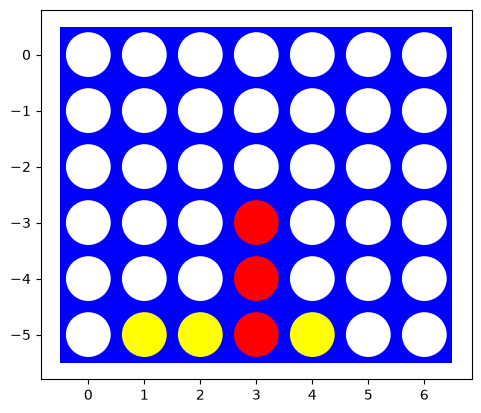

In [4]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

### [Bài 9] Cài đặt môi trường

- Bàn cờ là mảng numpy giống Bài 8: `1` là đỏ (đi trước), `-1` là vàng, `0` là ô trống, hàng 0 là hàng trên cùng.
- Nước đi là tuple: `('drop', c)` thả quân của mình vào cột `c`; `('mean', c_from, c_to)` lấy quân đối thủ ở đáy cột
  `c_from` rồi thả quân đó vào cột `c_to`.
- Theo Task 1, trạng thái gồm bàn cờ, người đến lượt và số nước đã đi. Vì vậy `actions` và `result` nhận thêm
  `player` (nước mean phụ thuộc quân nào là của đối thủ), còn `terminal` và `utility` nhận thêm `moves`, `max_moves`
  cho giới hạn số nước. Agent chỉ nhận `(board, player)` theo đề, nên số nước đã đi do môi trường đếm.
- Dùng lại `_line_windows` của Bài 8 để liệt kê mọi bộ 4 ô liên tiếp. Khác Bài 8, `winners` trả tập các bên đang có 4
  quân (sau một nước mean có thể là cả hai bên) thay vì bên đầu tiên tìm thấy. `_line_windows` được áp một lần lên bảng
  chỉ số ô, sau đó mỗi lần kiểm tra chỉ cần cộng tổng từng bộ 4 ô.
- Ô dưới kiểm thử luật trên nhiều kích thước bàn, gồm cả hai quy ước ở Task 1.

In [5]:
# [Bài 9] Task 2: môi trường Mean Connect 4.
# _line_windows lấy nguyên từ ô helper của Bài 8 (assignment_connect4.ipynb, #30); phần còn lại thêm luật "mean"
# và các quy ước ở Task 1 (cả hai cùng có 4 quân thì hòa, giới hạn số nước).
from functools import lru_cache

import pandas as pd
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view


def _line_windows(state):
    """Return groups of length-four windows in each available direction."""
    rows, cols = state.shape
    if cols >= 4:
        yield sliding_window_view(state, 4, axis=1)
    if rows >= 4:
        yield sliding_window_view(state.T, 4, axis=1)
    if rows >= 4 and cols >= 4:
        squares = sliding_window_view(state, (4, 4))
        yield np.diagonal(squares, axis1=-2, axis2=-1)
        yield np.diagonal(squares[..., ::-1], axis1=-2, axis2=-1)


@lru_cache(maxsize=None)
def _window_index(shape):
    # Áp _line_windows lên bảng chỉ số ô một lần cho mỗi kích thước bàn: mỗi hàng là chỉ số 4 ô của một bộ 4 ô liên tiếp.
    idx = np.arange(shape[0] * shape[1]).reshape(shape)
    parts = [windows.reshape(-1, 4) for windows in _line_windows(idx)]
    return np.concatenate(parts) if parts else np.empty((0, 4), dtype=int)


def winners(board):
    # Tập các bên đang có 4 quân liên tiếp. Nước mean có thể tạo 4 quân cho cả hai bên cùng lúc.
    board = np.asarray(board)
    sums = board.ravel()[_window_index(board.shape)].sum(axis=1)
    found = set()
    if (sums == 4).any():
        found.add(1)
    if (sums == -4).any():
        found.add(-1)
    return found


def default_max_moves(board):
    # Giới hạn số nước mặc định ở Task 1: 2 × rows × cols (84 nước với bàn 6 × 7).
    return 2 * np.size(board)


def utility(board, player, moves=0, max_moves=None):
    # +1 / -1 theo góc nhìn player; 0 nếu hòa (cả hai cùng có 4 quân, bàn đầy, hết số nước); None nếu chưa kết thúc.
    if player not in (1, -1):
        raise ValueError('player phải là 1 hoặc -1')
    board = np.asarray(board)
    if max_moves is None:
        max_moves = default_max_moves(board)
    found = winners(board)
    if len(found) == 1:
        return found.pop() * player
    if found or np.all(board[0] != 0) or moves >= max_moves:
        return 0
    return None


def terminal(board, moves=0, max_moves=None):
    return utility(board, 1, moves, max_moves) is not None


def legal_actions(board, player):
    # Mọi nước hợp lệ của player, không kiểm tra kết thúc (tìm kiếm tự kiểm tra trước khi sinh nước).
    board = np.asarray(board)
    cols = board.shape[1]
    acts = [('drop', c) for c in range(cols) if board[0, c] == 0]
    for c_from in range(cols):
        if board[-1, c_from] == -player:
            # Sau khi lấy quân, cột c_from luôn còn chỗ nên c_to = c_from luôn hợp lệ.
            acts += [('mean', c_from, c_to) for c_to in range(cols) if c_to == c_from or board[0, c_to] == 0]
    return acts


def actions(board, player, moves=0, max_moves=None):
    if terminal(board, moves, max_moves):
        return []
    return legal_actions(board, player)


def result(board, player, action):
    # Trả bàn mới, không sửa bàn cũ. Nước mean: bỏ quân đáy cột c_from, các quân phía trên rơi xuống một ô,
    # rồi thả quân vừa lấy (vẫn là quân đối thủ) vào cột c_to.
    if player not in (1, -1):
        raise ValueError('player phải là 1 hoặc -1')
    board = np.asarray(board)
    next_board = board.copy()
    if action[0] == 'drop':
        c = action[1]
        if not 0 <= c < board.shape[1] or board[0, c] != 0:
            raise ValueError(f'Không thả được vào cột {c}')
        next_board[np.flatnonzero(board[:, c] == 0)[-1], c] = player
        return next_board
    _, c_from, c_to = action
    if not 0 <= c_from < board.shape[1] or board[-1, c_from] != -player:
        raise ValueError(f'Đáy cột {c_from} không phải quân đối thủ')
    next_board[1:, c_from] = board[:-1, c_from]
    next_board[0, c_from] = 0
    if not 0 <= c_to < board.shape[1] or next_board[0, c_to] != 0:
        raise ValueError(f'Cột {c_to} đã đầy')
    next_board[np.flatnonzero(next_board[:, c_to] == 0)[-1], c_to] = -player
    return next_board


def board_from_rows(rows):
    return np.array(rows, dtype=int)


def expect_error(func, *args):
    try:
        func(*args)
    except ValueError:
        return True
    return False


checks = []
small = empty_board((3, 5))
checks.append(('Bàn 3 × 5 rỗng: chỉ có 5 nước thả quân, chưa có nước mean',
               actions(small, 1) == [('drop', c) for c in range(5)] and not terminal(small)))
after = result(small, 1, ('drop', 2))
checks.append(('Thả quân rơi xuống đáy, bàn gốc không đổi',
               after[:, 2].tolist() == [0, 0, 1] and np.count_nonzero(small) == 0))
b = board_from_rows([[0, 0, 0, 0, 0],
                     [0, 0, 0, 0, 0],
                     [0, 0, -1, 0, 0],
                     [1, 0, 1, 0, 0]])
mean = result(b, -1, ('mean', 2, 4))
checks.append(('Vàng lấy quân đỏ ở đáy cột 2: quân vàng phía trên rơi xuống, quân đỏ sang đáy cột 4',
               mean[:, 2].tolist() == [0, 0, 0, -1] and mean[:, 4].tolist() == [0, 0, 0, 1]
               and len(legal_actions(b, -1)) == 5 + 2 * 5))
same = result(b, -1, ('mean', 2, 2))
checks.append(('Nước mean về đúng cột cũ: quân đỏ chuyển từ đáy lên đỉnh cột',
               same[:, 2].tolist() == [0, 0, 1, -1]))
single = board_from_rows([[0, 0, 0], [1, 0, 0]])
checks.append(('Cột chỉ có một quân, mean về đúng cột cũ: bàn không đổi (tương đương bỏ lượt)',
               np.array_equal(result(single, -1, ('mean', 0, 0)), single)))
checks.append(('Từ chối: lấy quân của mình, lấy quân không ở đáy, thả vào cột ngoài bàn',
               expect_error(result, b, 1, ('mean', 0, 1)) and expect_error(result, b, 1, ('mean', 2, 1))
               and expect_error(result, after, 1, ('drop', 9)) and expect_error(result, b, -1, ('mean', 5, 0))))
win_by_mean = board_from_rows([[0, 0, 0, 0, 0],
                               [0, 0, 0, 0, 0],
                               [-1, -1, 0, 1, 0],
                               [1, 1, 1, -1, -1]])
after_mean = result(win_by_mean, 1, ('mean', 3, 4))
checks.append(('Đỏ thắng bằng nước mean (quân đỏ rơi xuống nối 4 ở hàng đáy)',
               utility(after_mean, 1) == 1 and utility(after_mean, -1) == -1))
both = board_from_rows([[0, 0, 0, 0, 0],
                        [0, 0, 0, -1, 0],
                        [-1, -1, -1, 1, 0],
                        [1, 1, 1, -1, 0]])
after_both = result(both, 1, ('mean', 3, 4))
checks.append(('Một nước mean tạo 4 quân cho cả hai bên: hòa',
               winners(after_both) == {1, -1} and utility(after_both, 1) == 0 and terminal(after_both)))
checks.append(('Đạt giới hạn số nước mà chưa ai thắng: hòa',
               utility(b, 1, moves=40) == 0 and utility(b, 1, moves=39) is None and actions(b, 1, moves=40) == []))
tiny = result(empty_board((1, 1)), 1, ('drop', 0))
checks.append(('Bàn 1 × 1 đầy sau một nước: hòa', utility(tiny, 1) == 0))
for name, ok in checks:
    print(f'{name} · {"đạt" if ok else "SAI"}')
assert all(ok for _, ok in checks)

Bàn 3 × 5 rỗng: chỉ có 5 nước thả quân, chưa có nước mean · đạt
Thả quân rơi xuống đáy, bàn gốc không đổi · đạt
Vàng lấy quân đỏ ở đáy cột 2: quân vàng phía trên rơi xuống, quân đỏ sang đáy cột 4 · đạt
Nước mean về đúng cột cũ: quân đỏ chuyển từ đáy lên đỉnh cột · đạt
Cột chỉ có một quân, mean về đúng cột cũ: bàn không đổi (tương đương bỏ lượt) · đạt
Từ chối: lấy quân của mình, lấy quân không ở đáy, thả vào cột ngoài bàn · đạt
Đỏ thắng bằng nước mean (quân đỏ rơi xuống nối 4 ở hàng đáy) · đạt
Một nước mean tạo 4 quân cho cả hai bên: hòa · đạt
Đạt giới hạn số nước mà chưa ai thắng: hòa · đạt
Bàn 1 × 1 đầy sau một nước: hòa · đạt


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
# [Bài 9] Agent ngẫu nhiên và môi trường chơi một ván.
rng = np.random.default_rng()


def random_player(board, player=1):
    # Chọn đều trong mọi nước hợp lệ, cả thả quân lẫn nước mean.
    acts = actions(board, player)
    if not acts:
        raise ValueError('Không còn nước hợp lệ')
    return acts[rng.integers(len(acts))]


def random_drop_player(board, player=1):
    # Đối chứng: chỉ chọn trong các nước thả quân, tức chơi như Connect 4 thường.
    acts = [a for a in actions(board, player) if a[0] == 'drop']
    if not acts:
        raise ValueError('Không còn nước thả quân')
    return acts[rng.integers(len(acts))]


def play_game(red_agent, yellow_agent, shape=(6, 7), max_moves=None):
    # Chơi một ván, đỏ (1) đi trước. Trả kết quả theo góc nhìn đỏ, lý do kết thúc và vài thống kê của ván.
    board = empty_board(shape)
    max_moves = default_max_moves(board) if max_moves is None else max_moves
    player, moves = 1, 0
    means = {1: 0, -1: 0}
    while True:
        action = (red_agent if player == 1 else yellow_agent)(board, player)
        means[player] += action[0] == 'mean'
        board = result(board, player, action)
        moves += 1
        score = utility(board, 1, moves, max_moves)
        if score is not None:
            found = winners(board)
            reason = ('4 quân' if len(found) == 1 else 'cả hai cùng có 4 quân' if found
                      else 'bàn đầy' if np.all(board[0] != 0) else 'hết số nước')
            return {'Kết quả': score, 'Lý do': reason, 'Số nước': moves,
                    'Nước mean của đỏ': means[1], 'Nước mean của vàng': means[-1],
                    'Quân đỏ - quân vàng': int((board == 1).sum() - (board == -1).sum())}
        player = -player


rng = np.random.default_rng(0)
print(play_game(random_player, random_player))

{'Kết quả': 1, 'Lý do': '4 quân', 'Số nước': 25, 'Nước mean của đỏ': 6, 'Nước mean của vàng': 8, 'Quân đỏ - quân vàng': 3}


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

### [Bài 9] Random đấu random 1000 ván

Thiết kế: hai `random_player` đấu 1000 ván trên bàn 6 × 7, giới hạn 84 nước, seed 31. Thêm cặp đối chứng
`random_drop_player` chỉ thả quân (tức chơi Connect 4 thường với cùng code) để tách ảnh hưởng của luật mean. Ghi thêm
tỷ lệ lượt chọn nước mean của mỗi bên và chênh lệch số quân lúc kết thúc ván.

In [7]:
# [Bài 9] Hai agent ngẫu nhiên đấu 1000 ván trên bàn 6 × 7, kèm cặp đối chứng chỉ thả quân.
GAMES = 1000
SEED = 31
rng = np.random.default_rng(SEED)
mean_games = pd.DataFrame([play_game(random_player, random_player) for _ in range(GAMES)])
rng = np.random.default_rng(SEED)
drop_games = pd.DataFrame([play_game(random_drop_player, random_drop_player) for _ in range(GAMES)])


def summarize(games, label):
    red_moves = (games['Số nước'] + 1) // 2
    yellow_moves = games['Số nước'] // 2
    return {'Cặp đấu': label,
            'Đỏ thắng (đi trước)': int((games['Kết quả'] == 1).sum()),
            'Vàng thắng (đi sau)': int((games['Kết quả'] == -1).sum()),
            'Hòa': int((games['Kết quả'] == 0).sum()),
            'Số nước TB': round(games['Số nước'].mean(), 1),
            '% lượt đỏ chọn mean': round(100 * games['Nước mean của đỏ'].sum() / red_moves.sum(), 1),
            '% lượt vàng chọn mean': round(100 * games['Nước mean của vàng'].sum() / yellow_moves.sum(), 1)}


print(f'{GAMES} ván mỗi cặp, seed {SEED}:')
display(pd.DataFrame([summarize(mean_games, 'random đấu random (mọi nước)'),
                      summarize(drop_games, 'chỉ thả quân (như Connect 4 thường)')]))
print('Lý do kết thúc của các ván random đấu random:')
display(mean_games['Lý do'].value_counts().rename('Số ván').to_frame())
print('Chênh lệch số quân đỏ - vàng lúc kết thúc ván (random đấu random):')
display(pd.DataFrame({'Trung bình': [mean_games['Quân đỏ - quân vàng'].mean()],
                      'Khi đỏ thắng': [mean_games.loc[mean_games['Kết quả'] == 1, 'Quân đỏ - quân vàng'].mean()],
                      'Khi vàng thắng': [mean_games.loc[mean_games['Kết quả'] == -1, 'Quân đỏ - quân vàng'].mean()]}).round(2))

1000 ván mỗi cặp, seed 31:


,Cặp đấu,Đỏ thắng (đi trước),Vàng thắng (đi sau),Hòa,Số nước TB,% lượt đỏ chọn mean,% lượt vàng chọn mean
0,random đấu random (mọi nước),760,232,8,25.1,44.9,69.0
1,chỉ thả quân (như Connect 4 thường),562,436,2,21.1,0.0,0.0


Lý do kết thúc của các ván random đấu random:


,Số ván
Lý do,
4 quân,992
cả hai cùng có 4 quân,7
hết số nước,1


Chênh lệch số quân đỏ - vàng lúc kết thúc ván (random đấu random):


,Trung bình,Khi đỏ thắng,Khi vàng thắng
0,3.26,5.02,-2.44


**Nhận xét.**
- Trong 1000 ván random đấu random, đỏ (đi trước) thắng 760, vàng thắng 232, hòa 8 ván. Lợi thế đi trước lớn hơn hẳn
  Connect 4 thường: cặp đối chứng chỉ thả quân cho 562 / 436 / 2 ván, gần với 573 / 424 / 3 ván ở Bài 8 (seed khác).
- Kết quả này giải thích được. Agent random chọn đều trong mọi nước hợp lệ, mà số nước mean tỷ lệ với số quân đối thủ
  ở hàng đáy (mỗi quân cho tối đa 7 nước mean, trong khi chỉ có tối đa 7 nước thả quân). Đỏ đi trước nên thường có
  nhiều quân ở đáy hơn, vì vậy vàng có nhiều nước mean hơn và chọn nước mean ở 69,0% số lượt, so với 44,9% của đỏ. Nước
  mean không thêm quân cho người đi mà chỉ dời quân của đối thủ, nên vàng tụt lại về số quân và lợi thế của đỏ tự tăng
  dần: lúc kết thúc, đỏ trung bình nhiều hơn vàng 3,26 quân (5,02 quân ở các ván đỏ thắng; ở các ván vàng thắng thì
  ngược lại, vàng nhiều hơn 2,44 quân).
- Đây là đặc điểm của agent random dưới luật mean, không có nghĩa người đi trước được lợi nhiều như vậy khi hai bên
  chơi tốt: agent biết chọn lúc nào dùng nước mean sẽ không tự bỏ lượt như vậy.
- Ván kết thúc nhanh, trung bình 25,1 nước (đối chứng 21,1 nước). 992 ván kết thúc vì một bên có 4 quân, 7 ván hòa vì
  một nước mean tạo 4 quân cho cả hai bên, và chỉ 1 ván chạm giới hạn 84 nước. Quy ước hòa khi cả hai cùng có 4 quân ở
  Task 1 vì vậy là trường hợp xảy ra thật chứ không chỉ trên lý thuyết.

## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

### [Bài 9] Thiết kế Alpha-Beta

- Dựa trên `alpha_beta_search` của Tic-Tac-Toe (Bài 3), viết thành class `AlphaBetaAgent` theo ghi chú của đề: class
  lưu cấu hình, số nút và thời gian của lần tìm gần nhất; gọi `agent(board, player)` trả nước đi như mọi agent khác.
- Cây trò chơi không tự kết thúc vì nước mean không thêm quân, nên "tìm tới hết ván" chỉ có nghĩa khi tính giới hạn
  số nước. Tham số `moves_left` là số nước còn lại trước giới hạn: chạm giới hạn mà chưa ai thắng thì hòa (giá trị 0),
  đúng luật ở Task 1. Khi `moves_left` bằng số nước còn lại thật của ván, kết quả là Minimax chính xác.
- Giá trị thắng là `1 - 0,01 × độ sâu` (thua thì lấy âm) để agent ưu tiên thắng sớm và trì hoãn thua; cả hai cùng có
  4 quân là 0.
- Hàm `order` sắp xếp các nút con trước khi duyệt (dùng ở phần move ordering); `cutoff` và `evaluate` dùng ở Task 4.

In [8]:
# [Bài 9] Task 3: Minimax với cắt tỉa Alpha-Beta.
import math
from time import perf_counter

WIN = 1.0


def natural_order(board, player, children):
    # Không sắp xếp: thả quân từ trái sang phải, rồi các nước mean theo thứ tự sinh ra.
    return children


class AlphaBetaAgent:
    """Minimax với cắt tỉa Alpha-Beta; class lưu cấu hình và thống kê của lần tìm gần nhất.

    moves_left: số nước còn lại trước giới hạn số nước (Task 1); chạm giới hạn thì hòa.
    order: hàm sắp xếp nước đi (move ordering).
    cutoff, evaluate: dùng ở Task 4, cắt ở độ sâu cutoff và trả giá trị heuristic.
    """

    def __init__(self, moves_left=None, order=natural_order, cutoff=None, evaluate=None):
        self.moves_left = moves_left
        self.order = order
        self.cutoff = cutoff
        self.evaluate = evaluate
        self.nodes, self.elapsed, self.last_value = 0, 0.0, None

    def __call__(self, board, player=1):
        return self.search(board, player)[0]

    def _children(self, board, player):
        return self.order(board, player, [(a, result(board, player, a)) for a in legal_actions(board, player)])

    def _value(self, board, to_move, depth, alpha, beta):
        self.nodes += 1
        found = winners(board)
        if found:
            if len(found) == 2:
                return 0.0
            # Thắng sớm tốt hơn thắng muộn, thua muộn tốt hơn thua sớm.
            return (WIN - 0.01 * depth) * (1 if self.me in found else -1)
        if np.all(board[0] != 0) or depth >= self.limit:
            return 0.0
        if self.cutoff is not None and depth >= self.cutoff:
            return self.evaluate(board, self.me)
        if to_move == self.me:
            value = -math.inf
            for _, child in self._children(board, to_move):
                value = max(value, self._value(child, -to_move, depth + 1, alpha, beta))
                if value >= beta:
                    return value
                alpha = max(alpha, value)
        else:
            value = math.inf
            for _, child in self._children(board, to_move):
                value = min(value, self._value(child, -to_move, depth + 1, alpha, beta))
                if value <= alpha:
                    return value
                beta = min(beta, value)
        return value

    def search(self, board, player=1):
        board = np.asarray(board)
        if terminal(board):
            raise ValueError('Ván đã kết thúc')
        self.me, self.nodes = player, 1
        self.limit = default_max_moves(board) if self.moves_left is None else self.moves_left
        start = perf_counter()
        best_action, best_value, alpha = None, -math.inf, -math.inf
        for action, child in self._children(board, player):
            value = self._value(child, -player, 1, alpha, math.inf)
            if value > best_value:
                best_action, best_value = action, value
            alpha = max(alpha, value)
        self.elapsed = perf_counter() - start
        self.last_value = best_value
        return best_action, best_value


agent = AlphaBetaAgent(moves_left=4)
print('Nước chọn trên bàn kiểm thử thắng bằng nước mean:', agent(win_by_mean, 1),
      f'| giá trị {agent.last_value:.2f} | {agent.nodes} nút | {1000 * agent.elapsed:.1f} ms')

Nước chọn trên bàn kiểm thử thắng bằng nước mean: ('mean', 3, 0) | giá trị 0.99 | 982 nút | 26.4 ms


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

### [Bài 9] Thử trên 5 thế cờ tự tạo

Thiết kế: 5 thế trên bàn 4 × 5, gồm thắng ngay bằng thả quân, thắng ngay bằng nước mean, chặn một đe dọa, hai đe dọa
mà chỉ nước mean cứu được, và một thế vàng đến lượt để kiểm tra `player = -1`. Đáp án chấm: nếu có nước thắng ngay
thì phải chọn một nước thắng ngay; nếu không thì phải chọn nước sau đó đối thủ không thắng ngay được. Mỗi thế chạy với
1, 2, 4 và 6 nước nhìn trước, thứ tự nước tự nhiên.

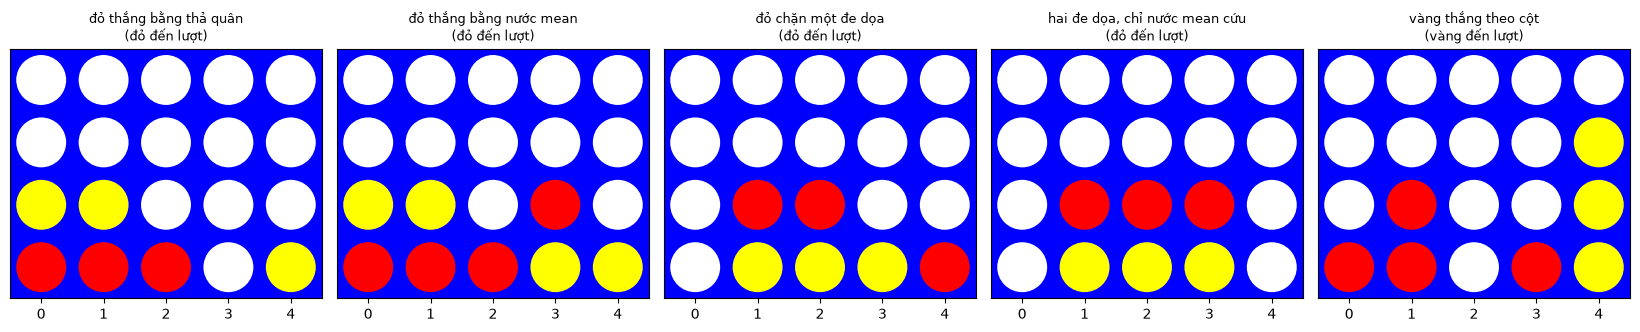

,Thế cờ,Nước nhìn trước,Nước chọn,Đúng,Nước đúng / hợp lệ,Giá trị,Số nút,Thời gian (ms)
0,đỏ thắng bằng thả quân,1,"(drop, 3)",True,1 / 10,0.99,11,0.1
1,đỏ thắng bằng thả quân,2,"(drop, 3)",True,1 / 10,0.99,39,0.8
2,đỏ thắng bằng thả quân,4,"(drop, 3)",True,1 / 10,0.99,627,13.8
3,đỏ thắng bằng thả quân,6,"(drop, 3)",True,1 / 10,0.99,8469,195.4
4,đỏ thắng bằng nước mean,1,"(mean, 3, 0)",True,5 / 15,0.99,16,0.1
5,đỏ thắng bằng nước mean,2,"(mean, 3, 0)",True,5 / 15,0.99,45,0.9
6,đỏ thắng bằng nước mean,4,"(mean, 3, 0)",True,5 / 15,0.99,982,25.8
7,đỏ thắng bằng nước mean,6,"(mean, 3, 0)",True,5 / 15,0.99,25035,706.0
8,đỏ chặn một đe dọa,1,"(drop, 0)",True,14 / 20,0.00,21,0.2
9,đỏ chặn một đe dọa,2,"(drop, 0)",True,14 / 20,0.00,55,1.1


In [9]:
# [Bài 9] Thử Alpha-Beta trên 5 thế cờ tự tạo (bàn 4 × 5).
TEST_BOARDS = {
    'đỏ thắng bằng thả quân': (1, board_from_rows([[0, 0, 0, 0, 0],
                                                    [0, 0, 0, 0, 0],
                                                    [-1, -1, 0, 0, 0],
                                                    [1, 1, 1, 0, -1]])),
    'đỏ thắng bằng nước mean': (1, win_by_mean),
    'đỏ chặn một đe dọa': (1, board_from_rows([[0, 0, 0, 0, 0],
                                                [0, 0, 0, 0, 0],
                                                [0, 1, 1, 0, 0],
                                                [0, -1, -1, -1, 1]])),
    'hai đe dọa, chỉ nước mean cứu': (1, board_from_rows([[0, 0, 0, 0, 0],
                                                           [0, 0, 0, 0, 0],
                                                           [0, 1, 1, 1, 0],
                                                           [0, -1, -1, -1, 0]])),
    'vàng thắng theo cột': (-1, board_from_rows([[0, 0, 0, 0, 0],
                                                 [0, 0, 0, 0, -1],
                                                 [0, 1, 0, 0, -1],
                                                 [1, 1, 0, 1, -1]])),
}


def immediate_wins(board, player):
    return {a for a in legal_actions(board, player) if winners(result(board, player, a)) == {player}}


def expected_moves(board, player):
    # Đáp án để chấm (không phải tác tử): các nước thắng ngay nếu có; nếu không thì các nước
    # không tự thua và sau đó đối thủ không thắng ngay được.
    wins = immediate_wins(board, player)
    if wins:
        return wins
    return {a for a in legal_actions(board, player)
            if not winners(child := result(board, player, a)) and not immediate_wins(child, -player)}


def draw_boards(boards, titles):
    # Vẽ nhiều bàn cạnh nhau theo cùng màu với hàm visualize; trục ngang ghi số cột.
    fig, axes = plt.subplots(1, len(boards), figsize=(3.3 * len(boards), 3.2))
    for ax, board, title in zip(np.atleast_1d(axes), boards, titles):
        rows, cols = board.shape
        ax.add_patch(plt.Rectangle((-0.5, -rows + 0.5), cols, rows, fc='blue'))
        for i in range(rows):
            for j in range(cols):
                color = 'white' if board[i, j] == 0 else 'red' if board[i, j] == 1 else 'yellow'
                ax.add_patch(plt.Circle((j, -i), 0.4, fc=color))
        ax.set_xlim(-0.5, cols - 0.5)
        ax.set_ylim(-rows + 0.5, 0.5)
        ax.set_aspect('equal')
        ax.set_xticks(range(cols))
        ax.set_yticks([])
        ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()


draw_boards([b for _, b in TEST_BOARDS.values()],
            [f'{name}\n({"đỏ" if p == 1 else "vàng"} đến lượt)' for name, (p, _) in TEST_BOARDS.items()])

rows = []
for name, (player, board) in TEST_BOARDS.items():
    expected = expected_moves(board, player)
    for moves_left in (1, 2, 4, 6):
        agent = AlphaBetaAgent(moves_left=moves_left)
        action, value = agent.search(board, player)
        rows.append({'Thế cờ': name, 'Nước nhìn trước': moves_left, 'Nước chọn': action,
                     'Đúng': action in expected,
                     'Nước đúng / hợp lệ': f'{len(expected)} / {len(legal_actions(board, player))}',
                     'Giá trị': round(value, 2), 'Số nút': agent.nodes,
                     'Thời gian (ms)': round(1000 * agent.elapsed, 1)})
test_ab = pd.DataFrame(rows)
display(test_ab)

**Nhận xét.**
- Từ 2 nước nhìn trước trở lên, agent chọn đúng ở cả 5 thế, kể cả thế phải thắng bằng nước mean (`('mean', 3, 0)`:
  lấy quân vàng ở đáy cột 3 để quân đỏ phía trên rơi xuống nối 4 ở hàng đáy) và thế vàng đến lượt (`player = -1`).
- Với 1 nước nhìn trước, agent chỉ thấy nước của mình nên ở thế "hai đe dọa" chọn sai `('drop', 0)`: chưa thấy vàng
  thắng ở nước sau. Ở thế "đỏ chặn một đe dọa", `('drop', 0)` đúng chỉ là tình cờ: mọi nước đều có giá trị 0, agent lấy
  nước đầu tiên và nước đó trùng nước chặn.
- Thế "hai đe dọa" cho thấy điểm riêng của Mean Connect 4: vàng có 3 quân ở hàng đáy với hai đầu trống, thả quân chỉ
  chặn được một đầu, nhưng một nước mean lấy quân vàng ở đáy phá được cả hàng. Trong Connect 4 thường, thế này là thua.
- Các thế thắng ngay có giá trị 0,99 (thắng ở độ sâu 1); các thế phòng thủ có giá trị 0 vì trong tầm nhìn không bên nào
  thắng được.
- Số nút tăng nhanh theo số nước nhìn trước: mỗi khi nhìn thêm 2 nước, số nút tăng khoảng 13-26 lần (ví dụ từ 627 lên
  8469 và từ 982 lên 25035 nút); ở 6 nước, mỗi nước mất 0,2-0,7 giây dù bàn chỉ có 4 × 5 ô.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

### [Bài 9] Thời gian mỗi nước khi tăng kích thước bàn

Thiết kế: một thế giữa ván cố định (hàng đáy 4 cột đầu là đỏ, vàng, đỏ, vàng; đỏ đến lượt) để có cả nước thả quân lẫn
nước mean. Bàn 4 hàng, tăng từ 4 lên 7 cột, nhìn trước 2, 4, 6 nước. Sau đó đo trên bàn 6 × 7 với 2-6 nước nhìn trước
và ngoại suy tới giới hạn 84 nước.

In [10]:
# [Bài 9] Thời gian mỗi nước khi tăng số cột (bàn 4 hàng), sau đó trên bàn chuẩn 6 × 7.
def midgame_board(rows, cols):
    # Thế giữa ván cố định: hàng đáy 4 cột đầu là đỏ, vàng, đỏ, vàng; đỏ đến lượt, có cả nước thả quân và nước mean.
    board = empty_board((rows, cols))
    board[-1, :4] = [1, -1, 1, -1]
    return board


rows = []
for cols in (4, 5, 6, 7):
    board = midgame_board(4, cols)
    for moves_left in (2, 4, 6):
        agent = AlphaBetaAgent(moves_left=moves_left)
        agent.search(board, 1)
        rows.append({'Bàn': f'4 × {cols}', 'Số nước hợp lệ': len(legal_actions(board, 1)),
                     'Nước nhìn trước': moves_left, 'Số nút': agent.nodes,
                     'Thời gian (ms)': round(1000 * agent.elapsed, 1)})
by_cols = pd.DataFrame(rows)
display(by_cols.pivot(index=['Bàn', 'Số nước hợp lệ'], columns='Nước nhìn trước', values=['Số nút', 'Thời gian (ms)']))

rows = []
board = midgame_board(6, 7)
for moves_left in (2, 3, 4, 5, 6):
    agent = AlphaBetaAgent(moves_left=moves_left)
    agent.search(board, 1)
    rows.append({'Nước nhìn trước': moves_left, 'Số nút': agent.nodes, 'Thời gian (ms)': round(1000 * agent.elapsed, 1)})
standard = pd.DataFrame(rows)
print('Bàn 6 × 7, cùng thế giữa ván:')
display(standard)

# Ngoại suy tới giới hạn 84 nước: hệ số tăng số nút mỗi nước đo từ 4 lên 6 nước nhìn trước.
nodes = dict(zip(standard['Nước nhìn trước'], standard['Số nút']))
growth = (nodes[6] / nodes[4]) ** 0.5
seconds_per_node = standard['Thời gian (ms)'].iloc[-1] / 1000 / nodes[6]
log10_nodes = math.log10(nodes[6]) + (84 - 6) * math.log10(growth)
log10_years = log10_nodes + math.log10(seconds_per_node / (3600 * 24 * 365))
print(f'Hệ số tăng số nút mỗi nước: {growth:.2f}; khoảng {1e6 * seconds_per_node:.0f} µs mỗi nút')
print(f'Ngoại suy tới 84 nước: khoảng 10^{log10_nodes:.0f} nút, tức khoảng 10^{log10_years:.0f} năm cho một nước đi')

Số nút                  Thời gian (ms)             
Nước nhìn trước           2       4        6              2     4      6
Bàn   Số nước hợp lệ                                                    
4 × 4 12               36.0   408.0   3280.0            0.8   9.0   73.9
4 × 5 15               45.0   651.0   7036.0            1.0  17.7  189.6
4 × 6 18               54.0   950.0  12924.0            1.4  27.7  408.5
4 × 7 21               63.0  1305.0  21418.0            2.3  43.8  768.9

Bàn 6 × 7, cùng thế giữa ván:


,Nước nhìn trước,Số nút,Thời gian (ms)
0,2,63,1.9
1,3,482,7.6
2,4,1307,42.3
3,5,8839,149.3
4,6,21830,797.5


Hệ số tăng số nút mỗi nước: 4.09; khoảng 37 µs mỗi nút
Ngoại suy tới 84 nước: khoảng 10^52 nút, tức khoảng 10^40 năm cho một nước đi


**Nhận xét.**
- Ở thế này, mỗi cột thêm vào làm tăng 3 nước hợp lệ: 1 nước thả quân và 2 nước mean (đỏ có 2 quân vàng ở đáy để lấy,
  mỗi quân thả được vào thêm 1 cột). Từ 4 lên 7 cột, với 6 nước nhìn trước, số nút tăng từ 3280 lên 21418 (khoảng 6,5
  lần) và thời gian từ 74 lên 769 ms.
- Số nút tăng theo hàm mũ của số nước nhìn trước: trên bàn 6 × 7, nhìn thêm mỗi nước làm số nút tăng khoảng 4,09 lần
  (đo từ 4 lên 6 nước). Đây là hệ số sau khi đã cắt tỉa; không cắt tỉa thì hệ số gần bằng số nước hợp lệ (21).
- Vì sao không dùng được trên bàn 6 × 7: Minimax chính xác phải tìm tới giới hạn 84 nước. Ngoại suy với hệ số 4,09 và
  khoảng 37 µs mỗi nút cho khoảng $10^{52}$ nút, tức khoảng $10^{40}$ năm cho một nước. Ước lượng này còn lạc quan: thế
  dùng để đo chưa có nước thắng nên hầu hết nhánh hòa và cắt tỉa rất hiệu quả, còn số nước hợp lệ tăng thêm khi hàng
  đáy có nhiều quân hơn. Connect 4 thường đã khó vì cây sâu tới 42 nước; Mean Connect 4 có nhánh rộng hơn và độ sâu
  gấp đôi.
- Vì vậy trên bàn chuẩn phải cắt tìm kiếm ở độ sâu nhỏ và dùng heuristic (Task 4).

### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

### [Bài 9] Move ordering

Ba cách sắp xếp nước đi:

- Không sắp xếp: thứ tự sinh nước (thả quân từ trái sang phải, rồi các nước mean).
- Cột giữa trước: thả quân trước nước mean, trong mỗi loại thì cột gần giữa trước. Quân ở giữa nằm trong nhiều bộ 4 ô
  hơn nên thường tốt hơn; nước mean xếp sau vì phần lớn nước mean (nhất là mean về cột cũ) hiếm khi là nước tốt nhất.
- Thắng ngay + cột giữa: đưa nước thắng ngay lên đầu, phần còn lại như trên. Ở nút của mình, nước thắng ngay cho giá
  trị cao nhất có thể nên cắt được hết các nước còn lại; ở nút của đối thủ, nước thắng của đối thủ được thử trước nên
  nhánh xấu bị loại sớm. Đổi lại phải kiểm tra thắng cho mọi nút con trước khi duyệt.

Thiết kế: 5 thế cờ ở trên và thế giữa ván 4 × 7, cùng 6 nước nhìn trước; mỗi cấu hình chạy 3 lần, lấy thời gian nhỏ
nhất để giảm nhiễu.

In [11]:
# [Bài 9] Move ordering: so sánh 3 cách sắp xếp nước đi với cùng 6 nước nhìn trước.
def center_order(board, player, children):
    # Thả quân trước nước mean; trong mỗi loại, cột (cột đích với nước mean) gần giữa bàn đi trước.
    center = (board.shape[1] - 1) / 2
    return sorted(children, key=lambda item: (item[0][0] == 'mean', abs(item[0][-1] - center)))


def win_center_order(board, player, children):
    # Nước thắng ngay lên đầu, phần còn lại như center_order.
    center = (board.shape[1] - 1) / 2
    return sorted(children, key=lambda item: (winners(item[1]) != {player}, item[0][0] == 'mean',
                                              abs(item[0][-1] - center)))


ORDERS = {'Không sắp xếp': natural_order, 'Cột giữa trước': center_order, 'Thắng ngay + cột giữa': win_center_order}
ORDER_BOARDS = dict(TEST_BOARDS)
ORDER_BOARDS['thế giữa ván 4 × 7'] = (1, midgame_board(4, 7))
ORDER_DEPTH = 6
REPEAT = 3

rows = []
for name, (player, board) in ORDER_BOARDS.items():
    for label, order in ORDERS.items():
        times = []
        for _ in range(REPEAT):
            agent = AlphaBetaAgent(moves_left=ORDER_DEPTH, order=order)
            action, value = agent.search(board, player)
            times.append(agent.elapsed)
        rows.append({'Thế cờ': name, 'Cách sắp xếp': label, 'Nước chọn': action, 'Giá trị': round(value, 2),
                     'Số nút': agent.nodes, 'Thời gian (ms)': round(1000 * min(times), 1)})
ordering = pd.DataFrame(rows)
table = ordering.pivot(index='Thế cờ', columns='Cách sắp xếp', values=['Số nút', 'Thời gian (ms)'])
table = table.reindex(columns=list(ORDERS), level=1).reindex(list(ORDER_BOARDS))
table.loc['Tổng'] = table.sum()
display(table)
same_value = ordering.groupby('Thế cờ')['Giá trị'].nunique().eq(1).all()
print('Giá trị Minimax giống nhau với mọi cách sắp xếp:', same_value)

Số nút                 \
Cách sắp xếp                  Không sắp xếp Cột giữa trước   
Thế cờ                                                       
đỏ thắng bằng thả quân               8469.0         5256.0   
đỏ thắng bằng nước mean             25035.0        19720.0   
đỏ chặn một đe dọa                  19903.0        27734.0   
hai đe dọa, chỉ nước mean cứu       19248.0        20940.0   
vàng thắng theo cột                 17407.0        10358.0   
thế giữa ván 4 × 7                  21418.0        27312.0   
Tổng                               111480.0       111320.0   

                                                    Thời gian (ms)  \
Cách sắp xếp                  Thắng ngay + cột giữa  Không sắp xếp   
Thế cờ                                                               
đỏ thắng bằng thả quân                        867.0          195.1   
đỏ thắng bằng nước mean                      1608.0          706.3   
đỏ chặn một đe dọa                          10151.0          469.8   
hai đe dọa, chỉ nước mean cứu                8173.0          472.2   
vàng thắng theo cột                           674.0          333.0   
thế giữa ván 4 × 7                          26363.0          749.5   
Tổng                                        47836.0         2925.9   

                                                                    
Cách sắp xếp                  Cột giữa trước Thắng ngay + cột giữa  
Thế cờ                                                              
đỏ thắng bằng thả quân                 130.3                  67.7  
đỏ thắng bằng nước mean                592.1                 106.1  
đỏ chặn một đe dọa                     597.6                 559.0  
hai đe dọa, chỉ nước mean cứu          488.9                 489.6  
vàng thắng theo cột                    211.5                  35.5  
thế giữa ván 4 × 7                     977.1                2080.1  
Tổng                                  2997.5                3338.0

Giá trị Minimax giống nhau với mọi cách sắp xếp: True


**Nhận xét.**
- Cả 3 cách cho cùng giá trị Minimax trên mọi thế (dòng in cuối), đúng như lý thuyết: sắp xếp chỉ đổi thứ tự duyệt chứ
  không đổi kết quả. Nước được chọn có thể khác khi nhiều nước cùng giá trị.
- Theo số nút, "Thắng ngay + cột giữa" tốt nhất: tổng 47836 nút so với 111480 khi không sắp xếp (giảm 57%). Ở 3 thế có
  nước thắng ngay, số nút giảm 10-26 lần (8469 xuống 867, 25035 xuống 1608, 17407 xuống 674). Ở 2 thế phòng thủ, số nút
  giảm khoảng một nửa vì nước thắng của vàng được thử trước nên nhánh xấu bị loại sớm.
- "Cột giữa trước" dùng một mình gần như không có tác dụng (tổng 111320 nút): ít nút hơn ở 3 thế nhưng nhiều hơn ở 3
  thế còn lại, ví dụ ở thế "đỏ chặn một đe dọa" nước chặn nằm ở cột 0 (cột biên) nên bị xếp sau.
- Thời gian không giảm theo số nút: kiểm tra thắng cho mọi nút con tốn thêm thời gian, kể cả với những nút con bị cắt
  và không bao giờ được duyệt. Ở thế có nước thắng, thời gian giảm 3-9 lần (195 xuống 68 ms, 706 xuống 106 ms, 333
  xuống 36 ms); ở 2 thế phòng thủ gần như không đổi; ở thế giữa ván 4 × 7 không có nước thắng nào trong tầm nhìn nên
  phần kiểm tra là chi phí thừa, thời gian tăng từ 750 lên 2080 ms. Tổng thời gian vì vậy gần như ngang nhau (khoảng
  2,9 / 3,0 / 3,3 giây).
- Kết luận: thứ tự nước có lợi rõ nhất ở thế có nước quyết định (thắng ngay hoặc phải chặn), cũng là lúc agent cần chọn
  đúng nhất. Trong Python, phần kiểm tra thêm khá đắt; có thể giảm bằng cách giữ lại kết quả kiểm tra thắng của nút con
  để dùng khi duyệt nút đó, thay vì tính lại.

### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

### [Bài 9] Nước đi đầu tiên trên bàn trống

Từ bàn trống, Minimax chính xác phải tìm tới giới hạn số nước của ván (32 nước với bàn 4 × 4, 84 nước với bàn 6 × 7)
mà gần như không có nhánh nào kết thúc sớm để cắt. Thiết kế:

- Đếm số chuỗi nước và số thế cờ khác nhau sau 1-6 nước từ bàn trống (bàn 4 × 4 và 6 × 7), để biết bao nhiêu phần của
  cây chỉ là thế cờ lặp lại.
- Thêm bảng lưu thế đã xét (transposition table) cho `AlphaBetaAgent` ở Task 3, viết thành class con
  `CachedAlphaBetaAgent`: gặp lại một thế ở cùng độ sâu thì dùng lại kết quả. Bảng lưu kèm loại cận (chính xác, cận
  dưới, cận trên) vì giá trị trả về sau khi cắt tỉa chỉ là cận. Tùy chọn `mirror` gộp thêm bàn đối xứng trái - phải.
- So sánh số nút và thời gian chọn nước đầu của 3 cấu hình, nhìn trước 4-10 nước trên bàn 4 × 4 và 4-8 nước trên bàn
  6 × 7. Alpha-Beta không có bảng lưu thế chỉ chạy tới 8 và 7 nước để giữ thời gian chạy notebook. Cả 3 cấu hình dùng
  thứ tự "Thắng ngay + cột giữa".

In [12]:
# [Bài 9] Nước đi đầu tiên: từ bàn trống, đếm thế cờ lặp lại và thử thêm bảng lưu thế đã xét cho Alpha-Beta.
def count_transpositions(shape, plies):
    # Từ bàn trống, đếm số chuỗi nước (số nút của cây khi không cắt tỉa) và số thế cờ khác nhau sau mỗi số nước.
    start = empty_board(shape)
    level = {start.tobytes(): 1}
    player, rows = 1, []
    for ply in range(1, plies + 1):
        nxt = {}
        for key, paths in level.items():
            board = np.frombuffer(key, dtype=start.dtype).reshape(shape)
            if winners(board):
                continue
            for action in legal_actions(board, player):
                child = result(board, player, action).tobytes()
                nxt[child] = nxt.get(child, 0) + paths
        level, player = nxt, -player
        rows.append({'Bàn': f'{shape[0]} × {shape[1]}', 'Số nước': ply, 'Số chuỗi nước': sum(level.values()),
                     'Số thế khác nhau': len(level)})
    return rows


EXACT, LOWER, UPPER = 'exact', 'lower', 'upper'


class CachedAlphaBetaAgent(AlphaBetaAgent):
    """AlphaBetaAgent của Task 3 thêm bảng lưu thế đã xét (transposition table).

    Khóa là (bàn, độ sâu): cùng bàn ở cùng độ sâu thì cùng bên đến lượt và cùng giá trị thắng/thua theo độ sâu.
    mirror=True gộp thêm bàn đối xứng qua cột giữa, vì luật chơi không đổi khi lật bàn trái - phải.
    Giá trị lưu kèm loại cận: chính xác, cận dưới (đã cắt ở nút Max) hoặc cận trên (đã cắt ở nút Min).
    """

    def __init__(self, *args, mirror=True, **kwargs):
        super().__init__(*args, **kwargs)
        self.mirror = mirror
        self.hits = 0

    def _key(self, board, depth):
        key = board.tobytes()
        if self.mirror:
            key = min(key, board[:, ::-1].tobytes())
        return key, depth

    def _value(self, board, to_move, depth, alpha, beta):
        key = self._key(board, depth)
        hit = self.table.get(key)
        if hit is not None:
            kind, value = hit
            if kind == EXACT or (kind == LOWER and value >= beta) or (kind == UPPER and value <= alpha):
                self.hits += 1
                return value
        value = super()._value(board, to_move, depth, alpha, beta)
        self.table[key] = (UPPER if value <= alpha else LOWER if value >= beta else EXACT, value)
        return value

    def search(self, board, player=1):
        # Bảng làm mới ở mỗi lần tìm vì độ sâu tính từ gốc của lần tìm đó.
        self.table, self.hits = {}, 0
        return super().search(board, player)


# Kiểm tra: bảng lưu thế không làm đổi giá trị Minimax trên các thế cờ đã dùng ở phần move ordering.
for name, (player, board) in ORDER_BOARDS.items():
    for moves_left in (2, 3, 4):
        plain = AlphaBetaAgent(moves_left=moves_left, order=win_center_order).search(board, player)[1]
        cached = CachedAlphaBetaAgent(moves_left=moves_left, order=win_center_order).search(board, player)[1]
        assert plain == cached, (name, moves_left)
print('Bảng lưu thế cho cùng giá trị với Alpha-Beta trên 6 thế cờ, nhìn trước 2-4 nước')

print('Số chuỗi nước và số thế cờ khác nhau từ bàn trống:')
trans = pd.DataFrame(count_transpositions((4, 4), 6) + count_transpositions((6, 7), 6))
trans['Chuỗi / thế'] = (trans['Số chuỗi nước'] / trans['Số thế khác nhau']).round(1)
display(trans.pivot(index='Số nước', columns='Bàn', values=['Số chuỗi nước', 'Số thế khác nhau', 'Chuỗi / thế']))

FIRST_AGENTS = {
    'Alpha-Beta (Task 3)': lambda d: AlphaBetaAgent(moves_left=d, order=win_center_order),
    'Bảng lưu thế': lambda d: CachedAlphaBetaAgent(moves_left=d, order=win_center_order, mirror=False),
    'Bảng lưu thế + đối xứng': lambda d: CachedAlphaBetaAgent(moves_left=d, order=win_center_order),
}
FIRST_RUNS = {(4, 4): (4, 6, 8, 10), (6, 7): (4, 5, 6, 7, 8)}
PLAIN_MAX = {(4, 4): 8, (6, 7): 7}  # Alpha-Beta không bảng lưu thế chỉ chạy tới đây để giữ thời gian chạy notebook.
rows = []
for shape, depths in FIRST_RUNS.items():
    for depth in depths:
        for label, make in FIRST_AGENTS.items():
            if label == 'Alpha-Beta (Task 3)' and depth > PLAIN_MAX[shape]:
                continue
            agent = make(depth)
            action, value = agent.search(empty_board(shape), 1)
            rows.append({'Bàn': f'{shape[0]} × {shape[1]}', 'Nước nhìn trước': depth, 'Cấu hình': label,
                         'Nước chọn': action, 'Giá trị': value, 'Số nút': agent.nodes,
                         'Thời gian (s)': round(agent.elapsed, 2)})
first = pd.DataFrame(rows)
assert first['Giá trị'].eq(0).all()
table = first.pivot(index=['Bàn', 'Nước nhìn trước'], columns='Cấu hình', values=['Số nút', 'Thời gian (s)'])
display(table.reindex(columns=list(FIRST_AGENTS), level=1))
for size in FIRST_RUNS:
    label = f'{size[0]} × {size[1]}'
    print(f'Bàn {label}, nước chọn ở mọi cấu hình và độ sâu:', sorted(set(first.loc[first['Bàn'] == label, 'Nước chọn'])))

# Ngoại suy tìm kiếm chính xác trên bàn 4 × 4 (giới hạn 32 nước) từ hệ số tăng số nút của cấu hình tốt nhất.
best = first[(first['Bàn'] == '4 × 4') & (first['Cấu hình'] == 'Bảng lưu thế + đối xứng')].set_index('Nước nhìn trước')
growth = (best.loc[10, 'Số nút'] / best.loc[8, 'Số nút']) ** 0.5
seconds_per_node = best.loc[10, 'Thời gian (s)'] / best.loc[10, 'Số nút']
log10_nodes = math.log10(best.loc[10, 'Số nút']) + (32 - 10) * math.log10(growth)
days = 10 ** log10_nodes * seconds_per_node / 86400
print(f'Bàn 4 × 4, bảng lưu thế + đối xứng: hệ số tăng số nút mỗi nước {growth:.2f}; ngoại suy tới 32 nước khoảng '
      f'10^{log10_nodes:.0f} nút, tức khoảng {days:.0f} ngày cho nước đầu')

Bảng lưu thế cho cùng giá trị với Alpha-Beta trên 6 thế cờ, nhìn trước 2-4 nước
Số chuỗi nước và số thế cờ khác nhau từ bàn trống:


Số chuỗi nước            Số thế khác nhau          Chuỗi / thế       
Bàn             4 × 4      6 × 7            4 × 4    6 × 7       4 × 4  6 × 7
Số nước                                                                      
1                 4.0        7.0              4.0      7.0         1.0    1.0
2                32.0       98.0             20.0     56.0         1.6    1.8
3               176.0      980.0             78.0    315.0         2.3    3.1
4              1744.0    17542.0            286.0   1645.0         6.1   10.7
5             11932.0   224567.0            884.0   6846.0        13.5   32.8
6            129536.0  4574493.0           2634.0  28385.0        49.2  161.2

Số nút               \
Cấu hình              Alpha-Beta (Task 3) Bảng lưu thế   
Bàn   Nước nhìn trước                                    
4 × 4 4                             154.0        118.0   
      6                            1480.0        624.0   
      8                           12986.0       2669.0   
      10                              NaN       9279.0   
6 × 7 4                             460.0        316.0   
      5                            2132.0       1012.0   
      6                            8193.0       2445.0   
      7                           39243.0       7010.0   
      8                               NaN      15172.0   

                                                    Thời gian (s)  \
Cấu hình              Bảng lưu thế + đối xứng Alpha-Beta (Task 3)   
Bàn   Nước nhìn trước                                               
4 × 4 4                                  74.0                0.00   
      6                                 398.0                0.04   
      8                                1743.0                0.39   
      10                               6164.0                 NaN   
6 × 7 4                                 169.0                0.02   
      5                                 528.0                0.07   
      6                                1265.0                0.36   
      7                                3573.0                1.29   
      8                                7716.0                 NaN   

                                                            
Cấu hình              Bảng lưu thế Bảng lưu thế + đối xứng  
Bàn   Nước nhìn trước                                       
4 × 4 4                       0.00                    0.00  
      6                       0.03                    0.01  
      8                       0.11                    0.07  
      10                      0.43                    0.30  
6 × 7 4                       0.02                    0.01  
      5                       0.05                    0.02  
      6                       0.16                    0.08  
      7                       0.39                    0.21  
      8                       1.13                    0.59

Bàn 4 × 4, nước chọn ở mọi cấu hình và độ sâu: [('drop', 1)]
Bàn 6 × 7, nước chọn ở mọi cấu hình và độ sâu: [('drop', 3)]
Bàn 4 × 4, bảng lưu thế + đối xứng: hệ số tăng số nút mỗi nước 1.88; ngoại suy tới 32 nước khoảng 10^10 nút, tức khoảng 4 ngày cho nước đầu


**Nhận xét.**
- Cây từ bàn trống có rất nhiều thế cờ lặp lại: sau 6 nước, bàn 6 × 7 có 4574493 chuỗi nước nhưng chỉ 28385 thế khác
  nhau, trung bình mỗi thế gặp lại 161,2 lần (bàn 4 × 4: 129536 chuỗi, 2634 thế, 49,2 lần). Tỷ lệ tăng nhanh theo số
  nước vì nước mean tạo lại các thế đã có. Ví dụ sau 2 nước trên bàn 4 × 4 chỉ còn 20 thế từ 32 chuỗi: đỏ thả quân ở cột
  nào thì vàng cũng có thể lấy đúng quân đó đặt vào cùng một cột, nên nhiều nước đầu khác nhau dẫn tới cùng một thế.
- Bảng lưu thế giảm số nút càng nhiều khi nhìn càng sâu: bàn 4 × 4 nhìn trước 8 nước giảm từ 12986 xuống 2669 nút, bàn 6
  × 7 nhìn trước 7 nước giảm từ 39243 xuống 7010 nút. Gộp thêm bàn đối xứng giảm tiếp khoảng một nửa (1743 và 3573 nút),
  vì bàn trống đối xứng nên mỗi cặp nước đối xứng chỉ cần tính một lần. Thời gian giảm tương ứng, ví dụ bàn 6 × 7 nhìn
  trước 7 nước: 1,29 giây, 0,39 giây và 0,21 giây.
- Kết quả không đổi: mọi cấu hình cho giá trị 0 và cùng nước (cột 1 trên bàn 4 × 4, cột 3 trên bàn 6 × 7), và ô kiểm tra
  cho cùng giá trị với Alpha-Beta gốc trên 6 thế cờ.
- Dù vậy vẫn chưa giải chính xác được: với bảng lưu thế và đối xứng, số nút trên bàn 4 × 4 vẫn tăng khoảng 1,88 lần mỗi
  nước nhìn trước; ngoại suy tới giới hạn 32 nước được khoảng $10^{10}$ nút, tức khoảng 4 ngày cho nước đầu. Bàn 6 × 7
  với giới hạn 84 nước thì xa hơn nhiều.

Có thể làm gì để chọn nước đầu?

- Bảng lưu thế và gộp đối xứng như trên: không đổi kết quả mà giảm số nút nhiều lần. Có thể giữ bảng qua các nước của
  cùng một ván nếu khóa theo số nước còn lại thay vì độ sâu tính từ gốc của mỗi lần tìm.
- Sổ khai cuộc: bàn trống lúc nào cũng giống nhau, nên có thể tính trước nước đầu (và vài nước tiếp theo) một lần, lưu
  lại rồi tra khi chơi.
- Cắt ở độ sâu nhỏ và dùng heuristic như Task 4, kết hợp tìm sâu dần có giới hạn thời gian: tìm với cutoff 1, 2, 3, ...
  và trả kết quả của mức sâu nhất đã xong trước hạn.
- Ở nước đầu chỉ có nước thả quân và bàn đối xứng, nên chỉ cần xét 4 cột thay vì 7.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

### [Bài 9] Minimax đấu random trên bàn nhỏ

Thiết kế: bàn 4 × 4 (giới hạn 32 nước), cùng kích thước bàn nhỏ ở Bài 8. Phần trên cho thấy không tìm chính xác được
tới hết ván ngay cả trên bàn này, nên agent Minimax nhìn trước có giới hạn: `CachedAlphaBetaAgent` với `moves_left` là
2 hoặc 4 nước, thế chưa kết thúc ở độ sâu đó được tính là hòa (giá trị 0), không dùng heuristic. Mỗi cấu hình cầm đỏ
100 ván rồi cầm vàng 100 ván với `random_player`, seed cố định. Ghi thắng, hòa, thua theo góc nhìn agent, số nước trung
bình mỗi ván, tỷ lệ nước mean trong các nước của agent, số nút và thời gian trung bình mỗi nước.

In [13]:
# [Bài 9] Minimax (nhìn trước có giới hạn, bảng lưu thế) đấu random trên bàn 4 × 4, mỗi bên 100 ván.
def play_vs_random(make_agent, opponent, label, shape=(4, 4), games=100, seed=42):
    # Agent cầm đỏ (đi trước) 100 ván rồi cầm vàng (đi sau) 100 ván; ghi kết quả theo góc nhìn agent.
    global rng
    rows = []
    for side in (1, -1):
        rng = np.random.default_rng(seed + (side == -1))
        agent = make_agent()
        stats = {'times': [], 'nodes': [], 'means': 0}

        def timed(board, player):
            action = agent(board, player)
            stats['times'].append(agent.elapsed)
            stats['nodes'].append(agent.nodes)
            stats['means'] += action[0] == 'mean'
            return action

        outcomes = [play_game(timed, opponent, shape) if side == 1 else play_game(opponent, timed, shape)
                    for _ in range(games)]
        scores = [o['Kết quả'] * side for o in outcomes]
        rows.append({'Agent': label, 'Bên agent': 'đỏ (đi trước)' if side == 1 else 'vàng (đi sau)',
                     'Thắng': scores.count(1), 'Hòa': scores.count(0), 'Thua': scores.count(-1),
                     'Số nước TB': round(np.mean([o['Số nước'] for o in outcomes]), 1),
                     '% nước mean của agent': round(100 * stats['means'] / len(stats['times']), 1),
                     'Số nút TB/nước': round(np.mean(stats['nodes'])),
                     'Thời gian TB/nước (ms)': round(1000 * np.mean(stats['times']), 1)})
    return rows


rows = []
for depth in (2, 4):
    rows += play_vs_random(lambda: CachedAlphaBetaAgent(moves_left=depth, order=win_center_order), random_player,
                           f'Minimax nhìn trước {depth} nước')
minimax_vs_random = pd.DataFrame(rows)
print('Bàn 4 × 4 (giới hạn 32 nước), 100 ván mỗi bên:')
display(minimax_vs_random)

Bàn 4 × 4 (giới hạn 32 nước), 100 ván mỗi bên:


,Agent,Bên agent,Thắng,Hòa,Thua,Số nước TB,% nước mean của agent,Số nút TB/nước,Thời gian TB/nước (ms)
0,Minimax nhìn trước 2 nước,đỏ (đi trước),98,2,0,11.3,1.0,20,0.8
1,Minimax nhìn trước 2 nước,vàng (đi sau),94,6,0,13.9,3.5,24,0.9
2,Minimax nhìn trước 4 nước,đỏ (đi trước),99,1,0,10.9,3.7,119,5.3
3,Minimax nhìn trước 4 nước,vàng (đi sau),98,2,0,13.7,4.4,150,6.4


**Nhận xét.**
- Agent Minimax gần như luôn thắng random: nhìn trước 2 nước thắng 98 ván khi cầm đỏ và 94 ván khi cầm vàng, nhìn trước
  4 nước thắng 99 và 98 ván; không thua ván nào, các ván còn lại hòa.
- Nhìn trước 2 nước (nước của mình và nước đáp của đối thủ) đã đủ: agent thắng ngay khi có thể và không để đối thủ thắng
  ngay ở nước sau, còn random hiếm khi tự tạo được hai đe dọa cùng lúc. Nhìn trước 4 nước chỉ thêm vài ván thắng.
- Agent ít dùng nước mean: 1,0-4,4% số nước của agent, trong khi random chọn nước mean ở 44,9-69,0% số lượt (Task 2, bàn
  6 × 7). Nước mean không thêm quân, và thứ tự nước đặt thả quân trước nên khi các nước có cùng giá trị thì agent thả
  quân; agent chỉ dùng nước mean khi nó có giá trị cao hơn các nước thả quân, tức để thắng hoặc để phá đe dọa.
- Ván ngắn, trung bình 10,9-13,9 nước trong giới hạn 32 nước. Số nút trung bình mỗi nước là 20-24 khi nhìn trước 2 nước
  và 119-150 khi nhìn trước 4 nước; thời gian dưới 1 ms và khoảng 5-6 ms mỗi nước.
- Bài 8 (Connect 4 thường, tìm tới hết ván trên bàn 4 × 4) thắng 42 và 84 ván, hòa 58 và 16 ván. Agent ở đây thắng nhiều
  hơn dù chỉ nhìn trước vài nước; phần so sánh ở cuối notebook chạy cùng agent này với luật Connect 4 thường để tách ảnh
  hưởng của luật.

## Task 4: Heuristic Alpha-Beta Tree Search [3 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

### [Bài 9] Hàm heuristic

- Xét mọi bộ 4 ô liên tiếp (cùng bảng chỉ số với `winners`). Bộ chỉ có quân của mình, gồm $k$ quân và còn lại là ô
  trống, được cộng $w_k$; bộ chỉ có quân đối thủ bị trừ $w_k$; bộ có quân của cả hai bên không thể thành 4 quân nên bỏ
  qua. Trọng số $w_1, w_2, w_3 = 1, 4, 16$ tăng nhanh vì bộ 3 quân chỉ còn một nước là thắng.
- Giá trị được nén bằng $0{,}5 \tanh(\text{score} / 50)$ nên luôn nằm trong $(-0{,}5;\ 0{,}5)$, giữa giá trị thua và
  thắng (từ 0,9 trở lên khi thắng trong 10 nước). Nhờ vậy agent không bao giờ coi một thế chưa kết thúc tốt hơn một
  nước thắng thật.
- Heuristic đối xứng: giá trị cho đỏ bằng âm giá trị cho vàng (kiểm tra bằng `assert` ở ô dưới).
- Hạn chế: heuristic chưa tính luật mean. Quân ở hàng đáy có thể bị đối thủ lấy đi và cả cột phía trên rơi xuống, nên
  bộ 4 ô dựa vào quân hàng đáy kém chắc chắn hơn so với Connect 4 thường. Có thể thêm yếu tố này cho heuristic thứ hai
  ở phần cho hai agent heuristic đấu nhau.

In [14]:
# [Bài 9] Task 4: hàm heuristic.
HEURISTIC_WEIGHTS = np.array([0, 1, 4, 16, 0])


def heuristic(board, player, weights=HEURISTIC_WEIGHTS, scale=50):
    # Xét mọi bộ 4 ô liên tiếp: bộ chỉ có k quân của player (còn lại trống) cộng weights[k], bộ chỉ có k quân
    # đối thủ trừ weights[k]; bộ có quân của cả hai bên không còn dùng được nên bỏ qua. Tổng được nén về
    # khoảng (-0,5; 0,5) bằng tanh, luôn nhỏ hơn giá trị thắng/thua (từ 0,9 trở lên khi thắng trong 10 nước).
    board = np.asarray(board)
    cells = board.ravel()[_window_index(board.shape)]
    own = (cells == player).sum(axis=1)
    opp = (cells == -player).sum(axis=1)
    score = weights[own[opp == 0]].sum() - weights[opp[own == 0]].sum()
    return 0.5 * np.tanh(score / scale)


def pad_board(board, shape=(6, 7)):
    # Đặt thế cờ nhỏ vào góc dưới bên trái bàn lớn; hàng đáy vẫn là hàng đáy nên luật mean không đổi.
    big = empty_board(shape)
    big[shape[0] - board.shape[0]:, :board.shape[1]] = board
    return big


rows = []
for name, (player, board) in TEST_BOARDS.items():
    big = pad_board(board)
    rows.append({'Thế cờ (bàn 6 × 7)': name, 'Bên đến lượt': 'đỏ' if player == 1 else 'vàng',
                 'h(đỏ)': round(heuristic(big, 1), 3), 'h(vàng)': round(heuristic(big, -1), 3)})
    assert abs(heuristic(big, 1) + heuristic(big, -1)) < 1e-12
rows.append({'Thế cờ (bàn 6 × 7)': 'bàn trống', 'Bên đến lượt': 'đỏ',
             'h(đỏ)': heuristic(empty_board(), 1), 'h(vàng)': heuristic(empty_board(), -1)})
display(pd.DataFrame(rows))

,Thế cờ (bàn 6 × 7),Bên đến lượt,h(đỏ),h(vàng)
0,đỏ thắng bằng thả quân,đỏ,0.070,-0.070
1,đỏ thắng bằng nước mean,đỏ,0.000,0.000
2,đỏ chặn một đe dọa,đỏ,-0.030,0.030
3,"hai đe dọa, chỉ nước mean cứu",đỏ,0.079,-0.079
4,vàng thắng theo cột,vàng,-0.030,0.030
5,bàn trống,đỏ,0.000,0.000


**Nhận xét.** Bàn trống cho 0 và giá trị cho đỏ luôn bằng âm giá trị cho vàng. Trên các thế thử, giá trị nhỏ
($|h| < 0{,}08$) vì bàn 6 × 7 còn nhiều bộ 4 ô trống và mỗi thế chỉ có vài quân. Heuristic chỉ đếm quân, không biết bên
nào đến lượt và ô còn thiếu có đi được ngay hay không (ô đó đã có quân bên dưới chưa). Vì vậy ở thế "hai đe dọa", nó
vẫn cho đỏ hơi lợi (0,079) dù vàng có 3 quân ở hàng đáy đi được ngay. Heuristic chỉ là ước lượng thô; các đe dọa trực
tiếp phải do phần tìm kiếm phát hiện.

### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

### [Bài 9] Cắt tìm kiếm ở độ sâu cutoff

Không viết thuật toán mới: `AlphaBetaAgent` ở Task 3 đã có `cutoff` và `evaluate`. Khi độ sâu đạt `cutoff` mà ván chưa
kết thúc, agent trả giá trị heuristic thay vì đi tiếp. Thứ tự nước dùng "Thắng ngay + cột giữa" vì cách này giảm số
nút nhiều nhất ở phần move ordering. Thiết kế: thế giữa ván trên bàn 6 × 7, cutoff từ 1 đến 6.

In [15]:
# [Bài 9] Cắt tìm kiếm ở độ sâu cutoff và dùng heuristic: chính AlphaBetaAgent ở Task 3 với cutoff và evaluate.
def heuristic_agent(cutoff, order=win_center_order, evaluate=heuristic):
    # Agent không biết ván đã đi bao nhiêu nước nên lấy giới hạn mặc định của bàn; độ sâu thực tế do cutoff quyết định.
    return AlphaBetaAgent(cutoff=cutoff, evaluate=evaluate, order=order)


rows = []
board = midgame_board(6, 7)
for cutoff in range(1, 7):
    agent = heuristic_agent(cutoff)
    action, value = agent.search(board, 1)
    rows.append({'Cutoff': cutoff, 'Nước chọn': action, 'Giá trị': round(value, 3),
                 'Số nút': agent.nodes, 'Thời gian (ms)': round(1000 * agent.elapsed, 1)})
print('Thế giữa ván trên bàn 6 × 7, đỏ đến lượt:')
display(pd.DataFrame(rows))

Thế giữa ván trên bàn 6 × 7, đỏ đến lượt:


,Cutoff,Nước chọn,Giá trị,Số nút,Thời gian (ms)
0,1,"(drop, 3)",0.099,22,0.6
1,2,"(drop, 3)",-0.040,63,4.8
2,3,"(drop, 3)",0.146,546,19.9
3,4,"(drop, 3)",-0.050,1590,130.5
4,5,"(drop, 3)",0.146,12296,475.7
5,6,"(drop, 2)",-0.060,38398,2874.1


**Nhận xét.**
- Số nút tăng nhanh theo cutoff: 22, 63, 546, 1590, 12296 và 38398 nút từ cutoff 1 đến 6; thời gian từ dưới 1 ms lên
  khoảng 2,9 giây. Cutoff 4 (khoảng 0,13 giây) là mức dùng được để chơi trên bàn 6 × 7; cutoff 6 đã mất vài giây mỗi
  nước.
- Giá trị dao động theo tính chẵn lẻ của cutoff: cutoff lẻ (lá là thế sau nước của đỏ) cho giá trị dương 0,099-0,146,
  cutoff chẵn (lá là thế sau nước của vàng) cho giá trị âm. Đây là hiệu ứng thường gặp khi cắt tìm kiếm: bên đi nước
  cuối trước khi đánh giá luôn có vẻ lợi hơn.
- Nước chọn ổn định ở `('drop', 3)` (cột giữa) với cutoff 1-5, cutoff 6 đổi sang `('drop', 2)`. Thế này chưa có đe dọa
  trực tiếp nên cả hai đều là nước hợp lý.

Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

### [Bài 9] Agent heuristic trên các thế cờ tự tạo

Thiết kế: 5 thế cờ ở Task 3 đặt vào góc dưới bên trái bàn 6 × 7 (hàng đáy giữ nguyên nên nước mean vẫn như cũ), cutoff
1-4, chấm theo cùng đáp án.

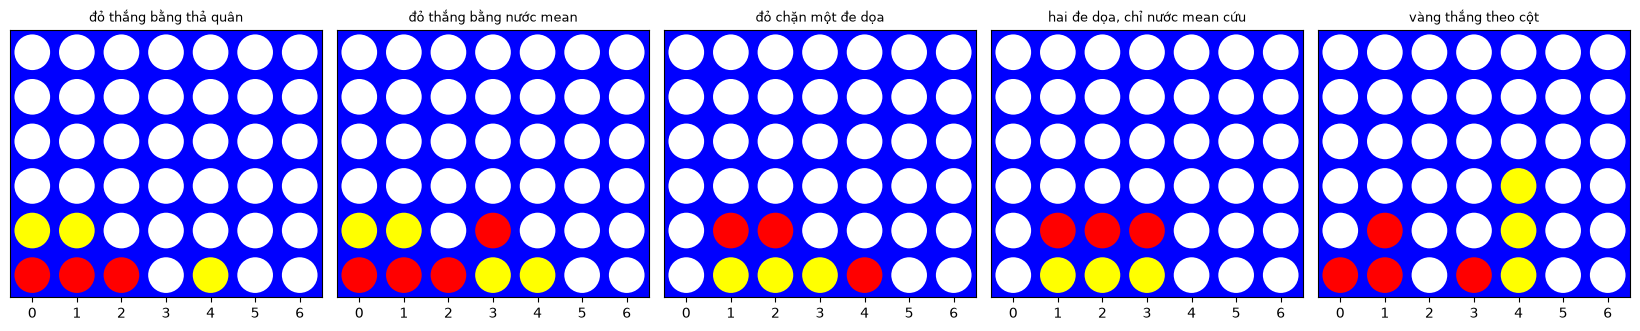

,Thế cờ,Cutoff,Nước chọn,Đúng,Nước đúng / hợp lệ,Giá trị,Số nút,Thời gian (ms)
0,đỏ thắng bằng thả quân,1,"(drop, 3)",True,1 / 14,0.990,15,0.4
1,đỏ thắng bằng thả quân,2,"(drop, 3)",True,1 / 14,0.990,28,3.4
2,đỏ thắng bằng thả quân,3,"(drop, 3)",True,1 / 14,0.990,273,10.1
3,đỏ thắng bằng thả quân,4,"(drop, 3)",True,1 / 14,0.990,518,72.5
4,đỏ thắng bằng nước mean,1,"(mean, 3, 3)",True,7 / 21,0.990,22,0.5
5,đỏ thắng bằng nước mean,2,"(mean, 3, 3)",True,7 / 21,0.990,36,3.8
6,đỏ thắng bằng nước mean,3,"(mean, 3, 3)",True,7 / 21,0.990,302,9.1
7,đỏ thắng bằng nước mean,4,"(mean, 3, 3)",True,7 / 21,0.990,470,55.8
8,đỏ chặn một đe dọa,1,"(drop, 3)",False,20 / 28,0.289,29,1.2
9,đỏ chặn một đe dọa,2,"(drop, 0)",True,20 / 28,-0.030,90,5.5


Cutoff,1,2,3,4
Thế cờ,,,,
đỏ thắng bằng thả quân,True,True,True,True
đỏ thắng bằng nước mean,True,True,True,True
đỏ chặn một đe dọa,False,True,True,True
"hai đe dọa, chỉ nước mean cứu",False,True,True,True
vàng thắng theo cột,True,True,True,True


In [16]:
# [Bài 9] Cùng 5 thế cờ, đặt vào bàn 6 × 7, với cutoff từ 1 đến 4.
draw_boards([pad_board(b) for _, b in TEST_BOARDS.values()], list(TEST_BOARDS))
rows = []
for name, (player, small_board) in TEST_BOARDS.items():
    board = pad_board(small_board)
    expected = expected_moves(board, player)
    for cutoff in (1, 2, 3, 4):
        agent = heuristic_agent(cutoff)
        action, value = agent.search(board, player)
        rows.append({'Thế cờ': name, 'Cutoff': cutoff, 'Nước chọn': action, 'Đúng': action in expected,
                     'Nước đúng / hợp lệ': f'{len(expected)} / {len(legal_actions(board, player))}',
                     'Giá trị': round(value, 3), 'Số nút': agent.nodes,
                     'Thời gian (ms)': round(1000 * agent.elapsed, 1)})
test_h = pd.DataFrame(rows)
display(test_h)
display(test_h.pivot(index='Thế cờ', columns='Cutoff', values='Đúng').reindex(list(TEST_BOARDS)))

**Nhận xét.**
- Với cutoff từ 2 trở lên, agent heuristic chọn đúng ở cả 5 thế trên bàn 6 × 7, giống Alpha-Beta ở Task 3 khi nhìn
  trước từ 2 nước trở lên.
- Cutoff 1 sai ở hai thế phòng thủ: agent chỉ nhìn một nước của mình rồi đánh giá bằng heuristic, nên chọn nước làm
  heuristic cao nhất (`('drop', 3)` và `('drop', 4)`, giá trị 0,289) mà không thấy vàng thắng ngay ở nước sau. Heuristic
  không thay được việc nhìn trước ít nhất một nước của đối thủ.
- Ở hai thế phòng thủ, nước chọn đổi theo cutoff và có cả nước mean lấy quân vàng ở đáy (`('mean', 3, 6)`,
  `('mean', 1, 6)`): lấy một quân trong hàng 3 quân của vàng là phá được đe dọa, còn quân bị lấy được đặt ở cột 6.
- Thời gian mỗi nước trên bàn 6 × 7 vẫn dưới 1 giây với cutoff 4 vì cutoff chặn độ sâu, trong khi Alpha-Beta không
  cutoff ở Task 3 không thể tìm tới hết ván trên bàn này.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

### [Bài 9] Thời gian mỗi nước của agent heuristic

Thiết kế: cùng thế giữa ván, bàn 6 hàng, tăng từ 4 lên 7 cột, cutoff 2, 4 và 6.

In [17]:
# [Bài 9] Thời gian mỗi nước của agent heuristic khi tăng số cột (bàn 6 hàng).
rows = []
for cols in (4, 5, 6, 7):
    board = midgame_board(6, cols)
    for cutoff in (2, 4, 6):
        agent = heuristic_agent(cutoff)
        agent.search(board, 1)
        rows.append({'Bàn': f'6 × {cols}', 'Số nước hợp lệ': len(legal_actions(board, 1)), 'Cutoff': cutoff,
                     'Số nút': agent.nodes, 'Thời gian (ms)': round(1000 * agent.elapsed, 1)})
by_cols_h = pd.DataFrame(rows)
display(by_cols_h.pivot(index=['Bàn', 'Số nước hợp lệ'], columns='Cutoff', values=['Số nút', 'Thời gian (ms)']))

Số nút                  Thời gian (ms)               
Cutoff                    2       4        6              2      4       6
Bàn   Số nước hợp lệ                                                      
6 × 4 12               39.0   875.0  12228.0            1.8   37.3   548.7
6 × 5 15               59.0  1213.0  13381.0            2.7   59.6   759.5
6 × 6 18               71.0  1159.0  13915.0            4.1   84.9  1090.2
6 × 7 21               63.0  1590.0  38398.0            4.6  126.7  2838.3

**Nhận xét.**
- Với cutoff 2 và 4, thời gian tăng vừa phải khi thêm cột (cutoff 4: từ 37 ms ở bàn 6 × 4 lên 127 ms ở bàn 6 × 7).
  Với cutoff 6, số nút tăng từ 12228 lên 38398 và thời gian từ khoảng 0,55 lên 2,8 giây.
- Số nút không tăng đều theo số cột: ở cutoff 6 gần như không đổi từ 4 đến 6 cột (12228, 13381, 13915 nút) rồi tăng gần
  3 lần ở 7 cột. Hiệu quả cắt tỉa phụ thuộc thế cờ cụ thể trên từng kích thước bàn, nên chỉ đo một thế thì chưa đủ để
  rút ra quy luật chính xác.
- Mỗi nút của agent heuristic tốn hơn ở Task 3 (kiểm tra thắng cho mọi nút con để sắp xếp, cộng với tính heuristic ở
  lá), nên thời gian tăng nhanh hơn số nút. Trong Python, cutoff 4 là mức hợp lý cho bàn 6 × 7 (dưới nửa giây mỗi
  nước), còn cutoff 6 đã mất gần 3 giây.

### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

### [Bài 9] Hai agent heuristic đấu nhau

- h1: hàm heuristic ở Task 4.
- h2: như h1, nhưng bộ 4 ô có quân của một bên nằm ở hàng đáy chỉ được tính một nửa trọng số cho bên đó, vì đối thủ có
  thể lấy quân hàng đáy bằng nước mean (ý đã nêu ở phần hạn chế của heuristic Task 4).
- Ba agent: cutoff 2 với h1, cutoff 4 với h1, cutoff 4 với h2; cả ba dùng bảng lưu thế và thứ tự "Thắng ngay + cột
  giữa".
- Hai cặp đấu: khác cutoff (2 và 4, cùng h1) và khác heuristic (h1 và h2, cùng cutoff 4). Agent quyết định xác định
  nên mỗi thứ tự đi chỉ cần một ván. Mỗi cặp đấu 2 ván, đổi bên đi trước, vì ở phần random đấu random bên đi trước có
  lợi rõ. Bàn 6 × 7, giới hạn 84 nước.

,Đỏ (đi trước),Vàng (đi sau),Kết quả,Lý do,Số nước,Nước mean đỏ / vàng,Quân đỏ - vàng,ms/nước đỏ,ms/nước vàng
0,"cutoff 2, h1","cutoff 4, h1",hòa,cả hai cùng có 4 quân,26,0 / 1,1,3,77
1,"cutoff 4, h1","cutoff 2, h1",đỏ thắng,4 quân,33,1 / 2,2,60,3
2,"cutoff 4, h1","cutoff 4, h2",đỏ thắng,4 quân,25,0 / 6,7,64,58
3,"cutoff 4, h2","cutoff 4, h1",hòa,cả hai cùng có 4 quân,33,2 / 1,0,57,66


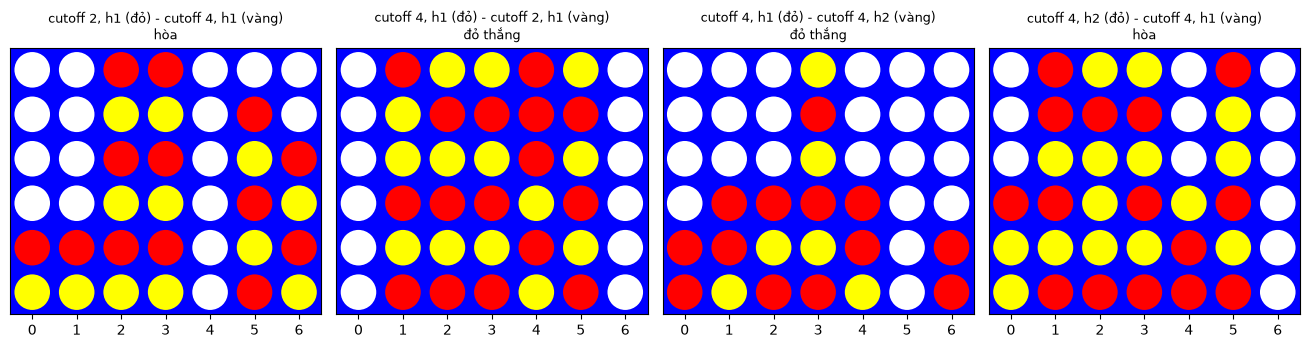

In [18]:
# [Bài 9] Hai agent heuristic đấu nhau trên bàn 6 × 7: khác cutoff, khác hàm heuristic.
@lru_cache(maxsize=None)
def _bottom_cells(shape):
    # Với mỗi bộ 4 ô (cùng thứ tự với _window_index): ô nào nằm ở hàng đáy.
    return _window_index(shape) >= (shape[0] - 1) * shape[1]


def mean_heuristic(board, player, weights=HEURISTIC_WEIGHTS, scale=50, bottom_factor=0.5):
    # Như heuristic ở Task 4, nhưng bộ 4 ô có quân của một bên ở hàng đáy chỉ được tính bottom_factor trọng số
    # của bên đó: đối thủ có thể lấy quân ở hàng đáy bằng nước mean và làm cả cột phía trên rơi xuống.
    board = np.asarray(board)
    cells = board.ravel()[_window_index(board.shape)]
    bottom = _bottom_cells(board.shape)
    own = (cells == player).sum(axis=1)
    opp = (cells == -player).sum(axis=1)
    own_w = weights[own] * np.where(((cells == player) & bottom).any(axis=1), bottom_factor, 1.0)
    opp_w = weights[opp] * np.where(((cells == -player) & bottom).any(axis=1), bottom_factor, 1.0)
    score = own_w[opp == 0].sum() - opp_w[own == 0].sum()
    return 0.5 * np.tanh(score / scale)


assert abs(mean_heuristic(midgame_board(6, 7), 1) + mean_heuristic(midgame_board(6, 7), -1)) < 1e-12

HEURISTIC_PLAYERS = {
    'cutoff 2, h1': lambda: CachedAlphaBetaAgent(cutoff=2, evaluate=heuristic, order=win_center_order),
    'cutoff 4, h1': lambda: CachedAlphaBetaAgent(cutoff=4, evaluate=heuristic, order=win_center_order),
    'cutoff 4, h2': lambda: CachedAlphaBetaAgent(cutoff=4, evaluate=mean_heuristic, order=win_center_order),
}
MATCHES = [('cutoff 2, h1', 'cutoff 4, h1'), ('cutoff 4, h1', 'cutoff 2, h1'),
           ('cutoff 4, h1', 'cutoff 4, h2'), ('cutoff 4, h2', 'cutoff 4, h1')]


def traced(agent, log, player_label):
    # Bọc agent để ghi thời gian, nước đi và thế cuối (play_game của Task 2 không trả bàn cuối).
    def act(board, player):
        action = agent(board, player)
        log.append({'Bên': player_label, 'Nước': action, 'Thời gian': agent.elapsed, 'Trước': board, 'Lượt': player})
        return action
    return act


rows, finals = [], []
for red_name, yellow_name in MATCHES:
    log = []
    outcome = play_game(traced(HEURISTIC_PLAYERS[red_name](), log, red_name),
                        traced(HEURISTIC_PLAYERS[yellow_name](), log, yellow_name))
    last = log[-1]
    finals.append(result(last['Trước'], last['Lượt'], last['Nước']))
    times = {name: [m['Thời gian'] for m in log if m['Bên'] == name] for name in (red_name, yellow_name)}
    rows.append({'Đỏ (đi trước)': red_name, 'Vàng (đi sau)': yellow_name,
                 'Kết quả': {1: 'đỏ thắng', -1: 'vàng thắng', 0: 'hòa'}[outcome['Kết quả']],
                 'Lý do': outcome['Lý do'], 'Số nước': outcome['Số nước'],
                 'Nước mean đỏ / vàng': f"{outcome['Nước mean của đỏ']} / {outcome['Nước mean của vàng']}",
                 'Quân đỏ - vàng': outcome['Quân đỏ - quân vàng'],
                 'ms/nước đỏ': round(1000 * np.mean(times[red_name])),
                 'ms/nước vàng': round(1000 * np.mean(times[yellow_name]))})
heuristic_games = pd.DataFrame(rows)
display(heuristic_games)
draw_boards(finals, [f'{r} (đỏ) - {y} (vàng)\n{res}' for (r, y), res in zip(MATCHES, heuristic_games['Kết quả'])])

**Nhận xét.**
- Trong 4 ván, bên đi trước không thua ván nào: 2 ván đỏ thắng và 2 ván hòa vì cả hai bên cùng có 4 quân.
- Khác cutoff: cutoff 4 cầm đỏ thắng cutoff 2 sau 33 nước; cutoff 2 cầm đỏ hòa với cutoff 4 sau 26 nước. Cutoff 4 không
  thua ván nào, nhưng 2 ván chưa đủ để nói chắc cutoff 4 mạnh hơn.
- Khác heuristic: h1 cầm đỏ thắng h2 sau 25 nước; h2 cầm đỏ hòa với h1 sau 33 nước. h2 không tỏ ra tốt hơn h1. Ở ván h1
  thắng, vàng (h2) dùng 6 nước mean để phá hàng của đỏ, nhưng mỗi nước mean là một lượt không thêm quân nên cuối ván đỏ
  nhiều hơn 7 quân và vẫn thắng. Đây là hiện tượng đã thấy ở random đấu random (Task 2), nay xuất hiện cả khi hai bên
  chơi có tính toán.
- Hai ván hòa đều kết thúc bằng một nước mean làm cả hai bên cùng có 4 quân (nước thả quân không thể tạo 4 quân cho đối
  thủ), do agent cutoff 4 đi (vàng ở ván 1, đỏ h2 ở ván 4). Với Minimax, nước này được chọn vì trong tầm nhìn không có
  nước nào có giá trị cao hơn hòa. Quy ước hòa khi cả hai cùng có 4 quân ở Task 1 vì vậy quyết định kết quả 2/4 ván.
- Thời gian mỗi nước khoảng 3 ms với cutoff 2 và 57-77 ms với cutoff 4 (có bảng lưu thế).
- Mỗi cặp chỉ có 2 ván và kết quả phụ thuộc nhiều vào bên đi trước. Muốn so sánh hai heuristic chắc chắn hơn cần cho
  chúng đấu từ nhiều thế xuất phát khác nhau, ví dụ các thế sau vài nước ngẫu nhiên.

## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

### [Bài 9] Pure Monte Carlo Search

- Cài theo notebook PMCS của Tic-Tac-Toe: với mỗi nước hợp lệ ở gốc, chơi N ván ngẫu nhiên từ thế sau nước đó (hai bên
  chọn đều trong mọi nước hợp lệ, kể cả nước mean), lấy trung bình kết quả +1, 0, -1 theo góc nhìn bên đến lượt và
  chọn nước có trung bình lớn nhất. Không có heuristic hay cây tìm kiếm; mỗi agent có bộ sinh số ngẫu nhiên riêng.
- Thiết kế: 5 thế cờ tự tạo, trên bàn 4 × 5 như Task 3 (N = 10, 40, 160 ván mỗi nước) và đặt vào bàn 6 × 7 như Task 4
  (N = 10, 40). Mỗi cấu hình chạy với 5 seed và chấm theo cùng đáp án `expected_moves`, ghi số seed chọn đúng.

In [19]:
# [Bài 9] Pure Monte Carlo Search với playout ngẫu nhiên, thử trên các thế cờ tự tạo.
class PureMonteCarloAgent:
    """Mỗi nước hợp lệ ở gốc được đánh giá bằng trung bình kết quả của n ván ngẫu nhiên chơi tiếp từ đó.

    Playout: hai bên chọn đều trong mọi nước hợp lệ (cả nước mean) như random_player, tới khi ván kết thúc
    hoặc chạm giới hạn số nước của bàn. drop_only=True chỉ dùng nước thả quân, tức Connect 4 thường.
    """

    def __init__(self, n=40, seed=0, drop_only=False):
        self.n = n
        self.rng = np.random.default_rng(seed)
        self.drop_only = drop_only
        self.playouts, self.elapsed, self.outcomes = 0, 0.0, {}

    def _actions(self, board, player):
        acts = legal_actions(board, player)
        return [a for a in acts if a[0] == 'drop'] if self.drop_only else acts

    def playout(self, board, to_move, me):
        # Agent không biết ván đã đi bao nhiêu nước nên playout dùng giới hạn mặc định của bàn.
        for _ in range(default_max_moves(board)):
            found = winners(board)
            if found:
                return 0 if len(found) == 2 else (1 if me in found else -1)
            if np.all(board[0] != 0):
                return 0
            acts = self._actions(board, to_move)
            board = result(board, to_move, acts[self.rng.integers(len(acts))])
            to_move = -to_move
        return 0

    def search(self, board, player=1):
        start = perf_counter()
        self.outcomes = {a: [self.playout(result(board, player, a), -player, player) for _ in range(self.n)]
                         for a in self._actions(board, player)}
        self.playouts = self.n * len(self.outcomes)
        values = {a: np.mean(v) for a, v in self.outcomes.items()}
        best = max(values, key=values.get)  # Bằng điểm thì giữ nước sinh ra trước.
        self.elapsed = perf_counter() - start
        return best, values[best]

    def __call__(self, board, player=1):
        return self.search(board, player)[0]


check = PureMonteCarloAgent(n=5, seed=0)
action, value = check.search(win_by_mean, 1)
assert value == 1 and np.mean(check.outcomes[('mean', 3, 0)]) == 1 and check.playouts == 5 * len(check.outcomes)

PMCS_RUNS = {'4 × 5': (10, 40, 160), '6 × 7': (10, 40)}
PMCS_SEEDS = range(5)
rows = []
for size, ns in PMCS_RUNS.items():
    for name, (player, board) in TEST_BOARDS.items():
        board = board if size == '4 × 5' else pad_board(board)
        expected = expected_moves(board, player)
        for n in ns:
            for seed in PMCS_SEEDS:
                agent = PureMonteCarloAgent(n=n, seed=seed)
                action, value = agent.search(board, player)
                rows.append({'Bàn': size, 'Thế cờ': name, 'N mỗi nước': n, 'Seed': seed, 'Nước chọn': action,
                             'Đúng': action in expected, 'Giá trị': value, 'Số playout': agent.playouts,
                             'Thời gian (ms)': 1000 * agent.elapsed})
pmcs_tests = pd.DataFrame(rows)
summary = pmcs_tests.groupby(['Bàn', 'Thế cờ', 'N mỗi nước'], sort=False).agg(
    **{'Đúng / 5 seed': ('Đúng', 'sum'), 'Thời gian TB (ms)': ('Thời gian (ms)', 'mean')}).round(0)
display(summary.unstack('N mỗi nước'))
print('Nước được chọn ở thế "hai đe dọa, chỉ nước mean cứu" (bàn 4 × 5):')
display(pmcs_tests[(pmcs_tests['Bàn'] == '4 × 5') & (pmcs_tests['Thế cờ'] == 'hai đe dọa, chỉ nước mean cứu')]
        .pivot(index='Seed', columns='N mỗi nước', values='Nước chọn'))

Đúng / 5 seed           Thời gian TB (ms)  \
N mỗi nước                                    10   40   160               10    
Bàn   Thế cờ                                                                    
4 × 5 đỏ thắng bằng thả quân                  5.0  5.0  5.0              26.0   
      đỏ thắng bằng nước mean                 5.0  5.0  5.0              22.0   
      đỏ chặn một đe dọa                      3.0  4.0  5.0              62.0   
      hai đe dọa, chỉ nước mean cứu           2.0  2.0  0.0              49.0   
      vàng thắng theo cột                     5.0  5.0  5.0              34.0   
6 × 7 đỏ thắng bằng thả quân                  3.0  5.0  NaN              50.0   
      đỏ thắng bằng nước mean                 2.0  5.0  NaN              41.0   
      đỏ chặn một đe dọa                      1.0  2.0  NaN             107.0   
      hai đe dọa, chỉ nước mean cứu           1.0  1.0  NaN              95.0   
      vàng thắng theo cột                     5.0  5.0  NaN              76.0   

                                                   
N mỗi nước                             40     160  
Bàn   Thế cờ                                       
4 × 5 đỏ thắng bằng thả quân          93.0  393.0  
      đỏ thắng bằng nước mean        113.0  350.0  
      đỏ chặn một đe dọa             229.0  866.0  
      hai đe dọa, chỉ nước mean cứu  192.0  764.0  
      vàng thắng theo cột            137.0  560.0  
6 × 7 đỏ thắng bằng thả quân         195.0    NaN  
      đỏ thắng bằng nước mean        166.0    NaN  
      đỏ chặn một đe dọa             424.0    NaN  
      hai đe dọa, chỉ nước mean cứu  383.0    NaN  
      vàng thắng theo cột            311.0    NaN

Nước được chọn ở thế "hai đe dọa, chỉ nước mean cứu" (bàn 4 × 5):


N mỗi nước,10,40,160
Seed,,,
0,"(drop, 0)","(drop, 0)","(drop, 0)"
1,"(drop, 3)","(mean, 2, 1)","(drop, 4)"
2,"(mean, 2, 3)","(drop, 4)","(drop, 4)"
3,"(drop, 4)","(drop, 4)","(drop, 4)"
4,"(mean, 2, 1)","(mean, 2, 1)","(drop, 0)"


**Nhận xét.**
- Thế thắng ngay: trên bàn 4 × 5, PMCS đúng 5/5 seed ở mọi N, vì mọi playout sau nước thắng ngay đều cho 1. Trên bàn 6 ×
  7 với N = 10, hai thế thắng ngay chỉ đúng 3/5 và 2/5: vài nước khác cũng thắng cả 10 playout (đối thủ random ít khi
  chặn), bằng điểm 1 với nước thắng ngay, và agent giữ nước sinh ra trước. Với N = 40 thì đúng 5/5. Thế vàng thắng theo
  cột đúng 5/5 ở cả hai bàn.
- Thế chặn một đe dọa: tăng N giúp chọn đúng hơn (4 × 5: 3, 4, 5 seed; 6 × 7: 1, 2 seed). Đối thủ random chỉ đi đúng
  nước thắng với xác suất nhỏ, nên cần nhiều playout thì chênh lệch giữa nước chặn và nước không chặn mới rõ.
- Thế hai đe dọa: số seed đúng là 2, 2 rồi 0 khi N tăng từ 10 lên 160, tức càng nhiều playout càng sai. Bảng cuối cho
  thấy với N = 160 agent chọn `('drop', 0)` hoặc `('drop', 4)`, tức chặn một đầu. PMCS ước lượng giá trị khi đối thủ
  chơi ngẫu nhiên: sau khi chặn một đầu, vàng random chỉ thắng nếu chọn đúng một trong nhiều nước hợp lệ, và nước thả
  quân còn thêm một quân cho đỏ, nên nhiều khả năng trong các ván ngẫu nhiên nó trông tốt hơn nước mean. Khi N tăng, ước
  lượng hội tụ về giá trị trước đối thủ ngẫu nhiên chứ không phải giá trị Minimax, nên PMCS không chọn được nước đúng.
  Alpha-Beta nhìn trước 2 nước ở Task 3 chọn đúng ở cả 5 thế.
- Thời gian tăng tuyến tính theo N: trên bàn 4 × 5 khoảng 22-62 ms với N = 10 và 350-866 ms với N = 160; trên bàn 6 × 7
  khoảng 166-424 ms với N = 40. Alpha-Beta nhìn trước 2 nước ở Task 3 chỉ mất khoảng 1 ms.
- Kết luận: PMCS không cần heuristic và tốt ở các thế có nước thắng ngay, nhưng yếu ở các thế phòng thủ cần thấy nước
  tốt nhất của đối thủ, vì playout ngẫu nhiên không mô phỏng một đối thủ biết chơi.

### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

### [Bài 9] Nước đi đầu tiên tốt nhất

Câu hỏi: làm sao xác định nước đi đầu tiên tốt nhất trên bàn 6 × 7?

- Ở nước đầu chỉ có 7 nước thả quân (chưa có quân đối thủ để lấy). Luật chơi không đổi khi lật bàn trái - phải nên cột
  c và cột 6 - c có cùng giá trị, thực chất chỉ có 4 lựa chọn.
- Cách chắc chắn là giải chính xác bằng Minimax tới hết ván, nhưng phần nước đi đầu tiên ở trên cho thấy không làm được,
  kể cả trên bàn 4 × 4. Vì vậy dùng hai cách ước lượng rồi đối chiếu:
  - PMCS với 1000 playout mỗi cột, kèm sai số chuẩn để biết chênh lệch giữa các cột có lớn hơn nhiễu không.
  - Alpha-Beta heuristic ở cutoff 2-5: giá trị của nước đầu ở cột c là âm giá trị của thế sau nước đó, nhìn từ phía
    vàng với cutoff - 1 nước còn lại.
- Chạy thêm PMCS với luật Connect 4 thường để đối chứng: Connect 4 thường đã được giải, bên đi trước thắng nếu bắt đầu
  ở cột giữa.

In [20]:
# [Bài 9] Nước đi đầu tiên tốt nhất trên bàn 6 × 7: PMCS với nhiều playout và Alpha-Beta heuristic ở nhiều cutoff.
FIRST_N = 1000
rows = []
for label, drop_only in (('PMCS, Mean Connect 4', False), ('PMCS, chỉ thả quân (Connect 4 thường)', True)):
    agent = PureMonteCarloAgent(n=FIRST_N, seed=65, drop_only=drop_only)
    agent.search(empty_board(), 1)
    means = {a[1]: np.mean(v) for a, v in agent.outcomes.items()}
    errors = {a[1]: np.std(v) / math.sqrt(len(v)) for a, v in agent.outcomes.items()}
    rows.append({'Cách đánh giá': label, **{c: round(means[c], 3) for c in range(7)}})
    rows.append({'Cách đánh giá': '  sai số chuẩn', **{c: round(errors[c], 3) for c in range(7)}})
    # Cột c và cột 6 - c có cùng giá trị thật nên gộp 2000 playout của hai cột để giảm nhiễu.
    pooled = {c: np.mean(agent.outcomes[('drop', c)] + agent.outcomes[('drop', 6 - c)]) for c in range(7)}
    rows.append({'Cách đánh giá': '  gộp hai cột đối xứng', **{c: round(pooled[c], 3) for c in range(7)}})
    print(f'{label}: {agent.playouts} playout, {agent.elapsed:.1f} s')

for cutoff in (2, 3, 4, 5):
    # Giá trị của nước đầu ở cột c = âm giá trị của thế sau nước đó, nhìn từ phía vàng, với cutoff - 1 nước còn lại.
    values = {}
    for c in range(7):
        agent = CachedAlphaBetaAgent(cutoff=cutoff - 1, evaluate=heuristic, order=win_center_order)
        values[c] = round(-agent.search(result(empty_board(), 1, ('drop', c)), -1)[1], 3)
    rows.append({'Cách đánh giá': f'Alpha-Beta heuristic, cutoff {cutoff}', **values})
best_first = pd.DataFrame(rows).set_index('Cách đánh giá')
best_first.columns = [f'cột {c}' for c in range(7)]
display(best_first)

PMCS, Mean Connect 4: 7000 playout, 2.7 s


PMCS, chỉ thả quân (Connect 4 thường): 7000 playout, 2.4 s


,cột 0,cột 1,cột 2,cột 3,cột 4,cột 5,cột 6
Cách đánh giá,,,,,,,
"PMCS, Mean Connect 4",0.572,0.553,0.565,0.533,0.523,0.590,0.596
sai số chuẩn,0.026,0.026,0.026,0.027,0.027,0.025,0.025
gộp hai cột đối xứng,0.584,0.572,0.544,0.533,0.544,0.572,0.584
"PMCS, chỉ thả quân (Connect 4 thường)",0.026,0.080,0.195,0.315,0.160,0.057,0.076
sai số chuẩn,0.032,0.031,0.031,0.030,0.031,0.032,0.031
gộp hai cột đối xứng,0.051,0.068,0.178,0.315,0.178,0.068,0.051
"Alpha-Beta heuristic, cutoff 2",-0.040,-0.030,-0.030,-0.030,-0.030,-0.030,-0.040
"Alpha-Beta heuristic, cutoff 3",0.060,0.070,0.099,0.089,0.099,0.070,0.060
"Alpha-Beta heuristic, cutoff 4",-0.060,-0.050,-0.020,-0.020,-0.020,-0.050,-0.060


**Nhận xét.**
- Với luật Connect 4 thường, PMCS phân biệt rõ: cột giữa 0,315, gộp cột 2 và 4 là 0,178, cột 1 và 5 là 0,068, cột 0 và 6
  là 0,051. Chênh lệch lớn hơn nhiều so với sai số chuẩn (khoảng 0,03), và khớp với lời giải đã biết là nên đi cột giữa.
- Với Mean Connect 4, điểm các cột chỉ từ 0,523 đến 0,596 với sai số chuẩn 0,025-0,027. Hai cột đối xứng, vốn có cùng
  giá trị thật, lệch nhau tới 0,042 (cột 2: 0,565, cột 4: 0,523), bằng cỡ chênh lệch giữa các cột. Sau khi gộp, cột 0 và
  6 cao nhất (0,584) còn cột 3 thấp nhất (0,533), nhưng chênh 0,051 chỉ khoảng 1,6 lần sai số của hiệu nên chưa đủ để
  kết luận. Điểm đều ở mức 0,53-0,60 chủ yếu phản ánh lợi thế đi trước khi random đấu random (đỏ thắng 76,0% ở Task 2).
- Vị trí quân đầu tiên ít quan trọng hơn ở Mean Connect 4 vì quân ở hàng đáy có thể bị đối thủ lấy và đặt sang cột khác
  bất cứ lúc nào; random chọn nước mean ở khoảng một nửa số lượt trở lên nên quân đầu thường không ở yên chỗ cũ.
- Alpha-Beta heuristic: cutoff chẵn và lẻ cho dấu khác nhau (hiệu ứng đã thấy ở Task 4), nhưng trong cùng một cutoff,
  các cột giữa (2, 3, 4) luôn cao hơn hoặc bằng các cột còn lại và cột 0, 6 thấp nhất. Cutoff 3 và 5 xếp cột 2 và 4
  (0,099 và 0,118) trên cột 3 (0,089).

Kết luận: chưa xác định chắc được nước đầu tốt nhất của Mean Connect 4. Nếu phải chọn thì nên đi một trong ba cột giữa,
vì heuristic ưu tiên các cột này và PMCS không cho thấy khác biệt vượt mức nhiễu. Để xác định chắc hơn có thể cho hai
agent mạnh (heuristic cutoff từ 4 trở lên) tự đấu nhiều ván từ mỗi nước đầu, hoặc dùng PMCS với playout chọn nước bằng
heuristic thay vì ngẫu nhiên. Cách chính xác là giải bằng một chương trình chuyên dụng như với Connect 4 thường, nhưng
phần nước đi đầu tiên ở trên cho thấy cách cài đặt trong notebook này chưa làm được, kể cả trên bàn 4 × 4.

### [Bài 9] So sánh hành vi tác tử giữa Connect 4 và Mean Connect 4

Thiết kế: dùng cùng code cho hai luật; Connect 4 thường là chỉ dùng nước thả quân (`random_drop_player` ở Task 2, và hàm
`drop_only` bọc thứ tự nước để agent Minimax bỏ nước mean ở cả hai bên). Như vậy khác biệt chỉ đến từ luật mean, không
đến từ cách cài đặt. Đo thêm: giải chính xác bàn nhỏ, Minimax nhìn trước 4 nước đấu random trên bàn 4 × 4 ở luật Connect
4 thường (cùng seed với phần Playtime), số nước hợp lệ trung bình mỗi lượt; sau đó gom với kết quả random đấu random
(Task 2) và nước đầu (PMCS) vào một bảng. Số liệu Bài 8 dùng để đối chiếu thêm.

In [21]:
# [Bài 9] So sánh Connect 4 thường và Mean Connect 4 bằng cùng code: Connect 4 thường = chỉ dùng nước thả quân.
def drop_only(order):
    # Bọc hàm sắp xếp nước: bỏ mọi nước mean ở cả hai bên, tức tìm kiếm theo luật Connect 4 thường.
    def ordered(board, player, children):
        return order(board, player, [c for c in children if c[0][0] == 'drop'])
    return ordered


def branching(player_fn, games=200, seed=66):
    # Số nước hợp lệ trung bình mỗi lượt (theo luật mà player_fn dùng) trong các ván random đấu random trên 6 × 7.
    global rng
    rng = np.random.default_rng(seed)
    counts = []

    def counting(board, player):
        legal = legal_actions(board, player)
        counts.append(len(legal) if player_fn is random_player else sum(a[0] == 'drop' for a in legal))
        return player_fn(board, player)

    for _ in range(games):
        play_game(counting, counting)
    return np.mean(counts)


solve = {}
for shape in ((4, 4), (4, 5)):
    agent = CachedAlphaBetaAgent(order=drop_only(win_center_order))
    action, value = agent.search(empty_board(shape), 1)
    solve[shape] = (action, value, agent.nodes, agent.elapsed)
    print(f'Connect 4 thường, bàn {shape[0]} × {shape[1]}: giải chính xác tới hết ván, chọn {action}, giá trị {value}, '
          f'{agent.nodes} nút, {agent.elapsed:.2f} s')

c4_vs_random = pd.DataFrame(play_vs_random(
    lambda: CachedAlphaBetaAgent(moves_left=4, order=drop_only(win_center_order)), random_drop_player,
    'Minimax nhìn trước 4 nước, Connect 4 thường'))
print('Bàn 4 × 4, 100 ván mỗi bên, cùng seed với phần Playtime:')
display(pd.concat([minimax_vs_random[minimax_vs_random['Agent'] == 'Minimax nhìn trước 4 nước'], c4_vs_random],
                  ignore_index=True))

mean_bf, drop_bf = branching(random_player), branching(random_drop_player)
red_share = lambda games: f"{100 * (games['Kết quả'] == 1).mean():.1f}%"
pmcs_rows = best_first.iloc[[0, 3]]
spread = lambda r: f'{r.min()} - {r.max()}, cao nhất {r.idxmax()}'
compare = pd.DataFrame({
    'Mean Connect 4': [f'{mean_bf:.1f}', red_share(mean_games), mean_games['Số nước'].mean().round(1),
                       f'không trong thời gian hợp lý (ngoại suy khoảng 10^{log10_nodes:.0f} nút)',
                       spread(pmcs_rows.iloc[0])],
    'Connect 4 thường': [f'{drop_bf:.1f}', red_share(drop_games), drop_games['Số nước'].mean().round(1),
                         f'có ({solve[(4, 4)][3]:.2f} s cho 4 × 4)',
                         spread(pmcs_rows.iloc[1])]},
    index=['Số nước hợp lệ TB mỗi lượt (random, 6 × 7)', 'Đỏ thắng khi random đấu random (1000 ván)',
           'Số nước TB mỗi ván (random)', 'Giải chính xác bàn 4 × 4 bằng Alpha-Beta + bảng lưu thế',
           'Điểm PMCS của 7 nước đầu trên 6 × 7'])
display(compare)

Connect 4 thường, bàn 4 × 4: giải chính xác tới hết ván, chọn ('drop', 1), giá trị 0.0, 11208 nút, 0.42 s


Connect 4 thường, bàn 4 × 5: giải chính xác tới hết ván, chọn ('drop', 2), giá trị 0.0, 65005 nút, 2.77 s


Bàn 4 × 4, 100 ván mỗi bên, cùng seed với phần Playtime:


,Agent,Bên agent,Thắng,Hòa,Thua,Số nước TB,% nước mean của agent,Số nút TB/nước,Thời gian TB/nước (ms)
0,Minimax nhìn trước 4 nước,đỏ (đi trước),99,1,0,10.9,3.7,119,5.3
1,Minimax nhìn trước 4 nước,vàng (đi sau),98,2,0,13.7,4.4,150,6.4
2,"Minimax nhìn trước 4 nước, Connect 4 thường",đỏ (đi trước),52,34,14,12.3,0.0,31,1.0
3,"Minimax nhìn trước 4 nước, Connect 4 thường",vàng (đi sau),63,33,4,13.5,0.0,31,1.0


,Mean Connect 4,Connect 4 thường
"Số nước hợp lệ TB mỗi lượt (random, 6 × 7)",20.6,6.8
Đỏ thắng khi random đấu random (1000 ván),76.0%,56.2%
Số nước TB mỗi ván (random),25.1,21.1
Giải chính xác bàn 4 × 4 bằng Alpha-Beta + bảng lưu thế,không trong thời gian hợp lý (ngoại suy khoảng...,có (0.42 s cho 4 × 4)
Điểm PMCS của 7 nước đầu trên 6 × 7,"0.523 - 0.596, cao nhất cột 6","0.026 - 0.315, cao nhất cột 3"


**Nhận xét.**
- Không gian tìm kiếm: luật mean làm số nước hợp lệ mỗi lượt tăng khoảng 3 lần (20,6 so với 6,8 trong các ván random
  trên bàn 6 × 7) và giới hạn số nước gấp đôi. Cùng code Alpha-Beta và bảng lưu thế giải chính xác Connect 4 thường trên
  bàn 4 × 4 trong 0,42 giây (11208 nút) và bàn 4 × 5 trong 2,77 giây (65005 nút), còn Mean Connect 4 trên bàn 4 × 4
  ngoại suy khoảng $10^{10}$ nút. Bài 8 dùng bitboard và cache giải bàn 4 × 4 trong 0,045 giây.
- Lợi thế đi trước lớn hơn: random đấu random cho đỏ thắng 76,0% so với 56,2%. Nước mean không thêm quân, nên bên dùng
  nhiều nước mean (thường là bên đi sau, vì có nhiều quân đối thủ ở đáy để lấy) tụt lại về số quân. Hai agent heuristic
  cũng vậy: bên đi trước không thua ván nào.
- Agent nhìn trước 4 nước đấu random trên bàn 4 × 4: với Mean Connect 4 thắng 99 và 98 ván, không thua; với Connect 4
  thường chỉ thắng 52 và 63 ván, hòa 34 và 33, thua 14 và 4. Ở Connect 4 thường trên bàn nhỏ, gần cuối ván các cột đầy
  dần và một bên có thể bị buộc phải đặt quân ngay dưới ô thắng của đối thủ; đe dọa kiểu này có thể hình thành từ sâu
  hơn 4 nước nên agent không thấy trước. Ở Mean Connect 4, bên phòng thủ có thêm nước mean để phá hàng của đối thủ, và
  random tự làm yếu mình bằng nước mean, nên nhìn trước ngắn vẫn đủ. Agent của Bài 8 tìm tới hết ván nên không thua,
  nhưng chỉ thắng 42 và 84 ván, có thể vì nó chỉ cần đạt giá trị hòa của bàn và không ưu tiên nước khiến random dễ sai.
- Cách agent dùng nước mean: agent dùng ít (1,0-4,4% số nước trên bàn 4 × 4) nhưng đúng lúc, như thắng bằng nước mean,
  lấy quân trong hàng 3 quân ở đáy của đối thủ (Task 3 và Task 4) hay chọn hòa bằng nước mean khi không có nước tốt hơn
  (ván heuristic). Agent của Connect 4 thường không có các lựa chọn này.
- Nước đầu: ở Connect 4 thường PMCS chọn rõ cột giữa (0,026-0,315), ở Mean Connect 4 các cột gần như ngang nhau
  (0,523-0,596, chênh lệch cỡ nhiễu).
- Tóm lại, luật mean làm cây rộng và sâu hơn nên phải dựa vào cutoff và heuristic sớm hơn; làm quân ở hàng đáy kém chắc
  chắn nên vị trí quân và heuristic đếm bộ 4 ô kém tin cậy hơn; và cho bên phòng thủ thêm cách phá hàng nhưng phải trả
  bằng một lượt không thêm quân.